In [1]:
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter
from typing import Dict, List, Optional, Tuple

In [15]:
METRICS = ["dci", "factorvae", "mig", "mse", "lpips"]

SAVE_FIGS = True
OUTDIR = "analysis_plots"
os.makedirs(OUTDIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="talk")

In [16]:
def final_valid_value(df: pd.DataFrame, metric: str):
    """Return final valid (non-NaN) value from df[metric], else None."""
    if df is None or df.empty or metric not in df.columns:
        return None
    s = df[metric].dropna()
    if len(s) == 0:
        return None
    v = s.iloc[-1]
    try:
        return float(v)
    except Exception:
        return None

# ----------------------------------------------------
# 1. Walk the directory and gather metrics per model_setting
#    Folder naming convention:
#      "<seed><model_setting>"
#    e.g. "0shapes3d_v_cosine_sech"
# ----------------------------------------------------
results = defaultdict(list)  # final values per run
curves = defaultdict(list)   # full curves per run (nimgs + metrics)

for folder in os.listdir(ROOT):
    folder_path = os.path.join(ROOT, folder)
    if not os.path.isdir(folder_path):
        continue

    # expect folder names like "0shapes3d_v_cosine_sech"
    try:
        seed = int(folder[0])
        model_setting = folder[1:]
    except Exception:
        # skip folders not matching the pattern
        continue

    metrics_path = os.path.join(folder_path, "metrics.csv")
    if not os.path.exists(metrics_path):
        print(f"Skipping {folder}, no metrics.csv")
        continue

    try:
        df = pd.read_csv(metrics_path)
    except Exception as e:
        print(f"Skipping {folder}, failed to read metrics.csv: {e}")
        continue

    # store final values robustly (handles empty cols / NaNs)
    entry = {}
    for m in METRICS:
        entry[m] = final_valid_value(df, m)

    # optionally skip runs with no usable values
    if all(entry[m] is None for m in METRICS):
        print(f"Skipping {folder}, metrics.csv has no usable metric values")
        continue

    results[model_setting].append(entry)

    # store full curve for training-efficiency plot
    needed_cols = ["nimgs"] + [m for m in METRICS if m in df.columns]
    if "nimgs" in df.columns:
        curves[model_setting].append(df[needed_cols].copy())

In [17]:
def smooth_curve(y, window=9, poly=3):
    """Savitzky–Golay smoothing with safe window handling."""
    n = len(y)
    if n < 3:
        return y
    w = min(window, n if n % 2 == 1 else n - 1)
    if w < 3:
        return y
    return savgol_filter(y, window_length=w, polyorder=min(poly, w - 1))


def parse_run_name_seedprefix(run_name: str) -> Tuple[str, Optional[int]]:
    """
    Parse '{seed}v_cosine_sech_dynamic1' -> (model_class, seed).

    We treat everything AFTER the first 'v' as the model class identifier.

    Example:
        '0v_cosine_sech_dynamic1' -> model_class='v_cosine_sech_dynamic1', seed=0
        '3v_cosine_sech_dynamic1' -> model_class='v_cosine_sech_dynamic1', seed|=3

    So {0-5}v_cosine_sech_dynamic1 are grouped together.
    """
    m = re.match(r"(?P<seed>\d+)v(?P<rest>.+)", run_name)
    if not m:
        # fallback: no seed prefix, treat whole name as model_class
        return run_name, None
    seed = int(m.group("seed"))
    rest = m.group("rest")
    model_class = "v" + rest
    return model_class, seed


def nth_difference(y: np.ndarray, n: int = 1) -> np.ndarray:
    """Nth-order forward finite differences. Length shrinks by n."""
    y = np.asarray(y, dtype=float)
    if n <= 0:
        return y
    if y.size <= n:
        return np.full_like(y, np.nan)
    return np.diff(y, n=n)


def pad_front(arr: np.ndarray, n: int) -> np.ndarray:
    """Pad with n NaNs at the front to keep same length as original."""
    if n <= 0:
        return arr
    return np.concatenate([np.full(n, np.nan), arr])


def load_dynamic_range(config_dir: str):
    """
    Look for a single *.json config in config_dir and read dynamic_min/max.
    Returns (dynamic_min, dynamic_max) or (None, None) if not found.
    """
    try:
        cfg_paths = glob.glob(os.path.join(config_dir, "*.json"))
        if not cfg_paths:
            return None, None
        import json
        with open(cfg_paths[0], "r") as f:
            cfg = json.load(f)
        w_cfg = cfg.get("weighting", {})
        return w_cfg.get("dynamic_min"), w_cfg.get("dynamic_max")
    except Exception:
        return None, None


def _safe_read_metrics(metrics_path: str) -> Optional[pd.DataFrame]:
    """Read metrics.csv robustly; return None if missing/empty/bad."""
    try:
        df = pd.read_csv(metrics_path)

        # skip header-only / empty metrics files
        if df is None or df.empty:
            return None

        # require nimgs for sorting/aligning
        if "nimgs" not in df.columns:
            return None

        df = df.sort_values("nimgs")
        return df
    except Exception:
        return None


def smooth_tail(x, y, after, window=31, poly=3):
    if after is None:
        return y
    y = y.copy()
    m = x >= after
    if m.sum() >= 3:
        y[m] = smooth_curve(y[m], window=window, poly=poly)
    return y


def plot_dis_vs_recon_per_model_class(
    base_dir: str,
    dis_col: str = "dci",
    lpips_col: str = "lpips",
    smooth: bool = True,
    window: int = 9,
    poly: int = 3,
    overlay_mean: bool = True,
    cmap_name: str = "viridis",
    out_dir: str = "analysis_plots/dis_vs_recon_by_model",
    file_ext: str = "pdf",
    show: bool = False,
    diff_order: int = 1,
    figsize = (7, 7),
    max_nimgs: float | None = None,
    tail_smooth_after: float | None = None,  # e.g. 150_000
    tail_window: int = 31,
    tail_poly: int = 3,
):
    """
    For each model class, generate ONE figure with two panels:
        (left)  dis vs mse
        (right) dis vs lpips

    Each seed/run is a trajectory line through checkpoints (nimgs).
    Line colour is determined by the run's FINAL disentanglement metric (dis_col),
    normalised WITHIN the model class (so colours are comparable within each figure).

    Optionally overlays the mean trajectory across seeds in black dashed.
    """
    os.makedirs(out_dir, exist_ok=True)

    run_dirs = [
        d for d in os.listdir(base_dir)
        if os.path.isdir(os.path.join(base_dir, d))
    ]
    run_dirs = sorted(run_dirs)
    if not run_dirs:
        raise RuntimeError(f"No run directories found in {base_dir}")

    # ---------- group runs by model_class ----------
    groups: Dict[str, List[str]] = {}
    seeds_by_run: Dict[str, Optional[int]] = {}
    for run_name in run_dirs:
        model_class, seed = parse_run_name_seedprefix(run_name)
        groups.setdefault(model_class, []).append(run_name)
        seeds_by_run[run_name] = seed

    # ---------- load metrics per run ----------
    per_run_df: Dict[str, pd.DataFrame] = {}
    for run_name in run_dirs:
        metrics_path = os.path.join(base_dir, run_name, "metrics.csv")
        if not os.path.exists(metrics_path):
            continue
        df = _safe_read_metrics(metrics_path)
        if df is None:
            continue
        per_run_df[run_name] = df

    # ---------- plot per model class ----------
    for model_class, runs in sorted(groups.items()):
        # valid runs: have metrics and required columns
        valid_runs = []
        for r in runs:
            df = per_run_df.get(r)
            if df is None:
                continue
            if not {dis_col, lpips_col}.issubset(df.columns):
                continue
            valid_runs.append(r)

        if len(valid_runs) == 0:
            continue

        # title label info (dynamic range if available)
        cfg_dir = os.path.join(base_dir, valid_runs[0], "configs")
        dyn_min, dyn_max = load_dynamic_range(cfg_dir)
        if dyn_min is not None and dyn_max is not None:
            title = f"{model_class}  [dynamic {dyn_min}, {dyn_max}]"
        else:
            title = model_class

        # compute final disentanglement per run (for colouring)
        final_dis_by_run: Dict[str, float] = {}
        for r in valid_runs:
            df = per_run_df[r]
            dis = df[dis_col].values.astype(float)
            if smooth:
                dis = smooth_curve(dis, window=window, poly=poly)
            final_dis_by_run[r] = float(dis[-1])

        dis_vals = np.array(list(final_dis_by_run.values()))
        d_min, d_max = float(dis_vals.min()), float(dis_vals.max())
        if np.isclose(d_min, d_max):
            d_max = d_min + 1e-6  # avoid zero range

        norm = plt.Normalize(vmin=0, vmax=0.65)
        cmap = plt.get_cmap(cmap_name)

        fig, axes = plt.subplots(1, 1, figsize=figsize)

        # For mean overlay we need a reference grid
        ref_nimgs = None
        dis_stack = []
        lp_stack = []

        # Plot each seed trajectory coloured by its final dis score
        def _sort_key(run_name: str):
            s = seeds_by_run.get(run_name)
            return (s is None, s if s is not None else 999999, run_name)

        for r in sorted(valid_runs, key=_sort_key):
            df = per_run_df[r]

            x = df["nimgs"].values.astype(float)
            dis = df[dis_col].values.astype(float)
            lp = df[lpips_col].values.astype(float)

            if max_nimgs is not None:
                m = x <= max_nimgs
                x, dis, lp = x[m], dis[m], lp[m]
                if len(x) < 2:
                    continue

            if smooth:
                dis = smooth_curve(dis, window=window, poly=poly)
                lp = smooth_curve(lp, window=window, poly=poly)

                dis = smooth_tail(x, dis, tail_smooth_after, window=tail_window, poly=tail_poly)
                lp  = smooth_tail(x, lp,  tail_smooth_after, window=tail_window, poly=tail_poly)

            colour = cmap(norm(final_dis_by_run[r]))

            axes.plot(
                lp,
                dis,
                linewidth=1.8,
                alpha=0.75,
                color=colour,
            )

            # stacks for mean overlay (interpolate to reference grid)
            if overlay_mean:
                if ref_nimgs is None:
                    ref_nimgs = x
                    dis_i, lp_i = dis, lp
                else:
                    dis_i = np.interp(ref_nimgs, x, dis)
                    lp_i = np.interp(ref_nimgs, x, lp)

                dis_stack.append(dis_i)
                lp_stack.append(lp_i)

        # Overlay mean trajectory (black dashed)
        if overlay_mean and len(dis_stack) > 0:
            dis_mean = np.mean(np.stack(dis_stack, axis=0), axis=0)
            lp_mean = np.mean(np.stack(lp_stack, axis=0), axis=0)

            axes.plot(
                lp_mean,
                dis_mean,
                color="black",
                linewidth=3.0,
                linestyle="--",
                alpha=0.95,
                label="mean",
            )

            # Optional: show only "mean" in a tiny legend
            ax_lp.legend(loc="best", fontsize=8, frameon=True)

        axes.set_xlim(left=-0.01, right=0.6)
        axes.set_ylim(bottom=-0.01, top=0.8)
        axes.set_xlabel(lpips_col)
        axes.set_ylabel(dis_col)
        axes.set_title(model_class)
        axes.grid(True, linestyle="--", alpha=0.3)

        # Colourbar (final dis_col) for this model-class figure
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])
        cbar = fig.colorbar(
            sm,
            ax=axes,
            fraction=0.046,
            pad=0.04,
        )

        if show:
            plt.tight_layout()
            plt.show()
        else:
            safe_name = re.sub(r"[^a-zA-Z0-9_\-]+", "_", model_class)
            out_path = os.path.join(out_dir, f"{safe_name}__{dis_col}_vs_recon.{file_ext}")
            fig.savefig(out_path, dpi=200, bbox_inches="tight")
            plt.close(fig)
            print(f"Saved {out_path}")

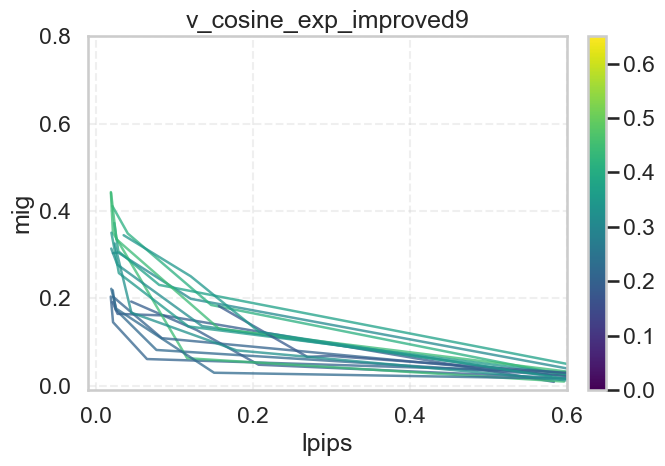

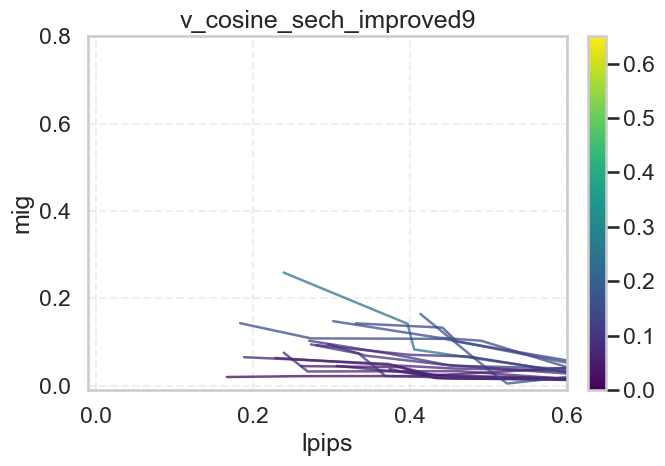

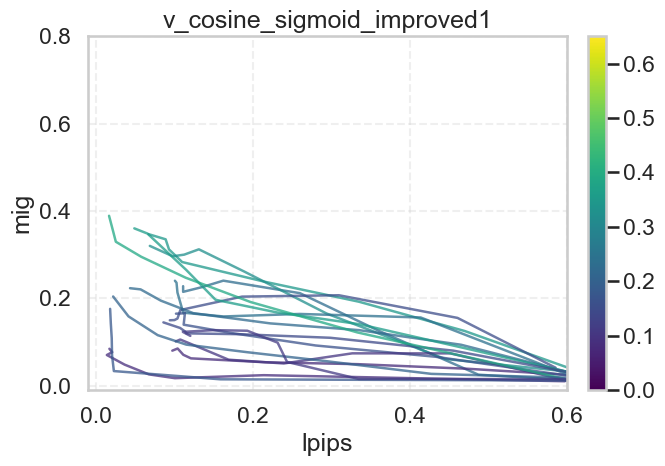

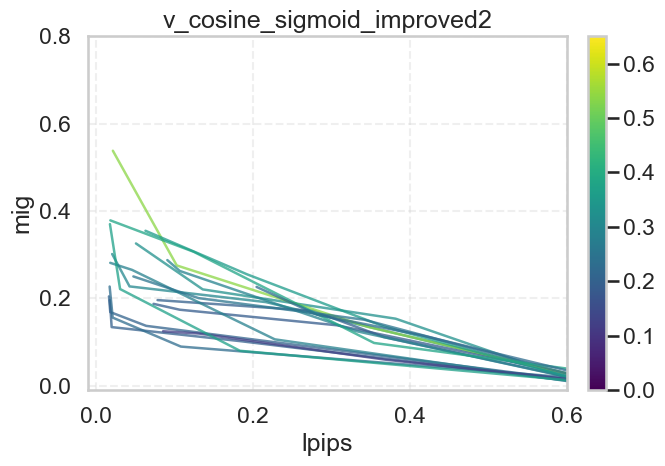

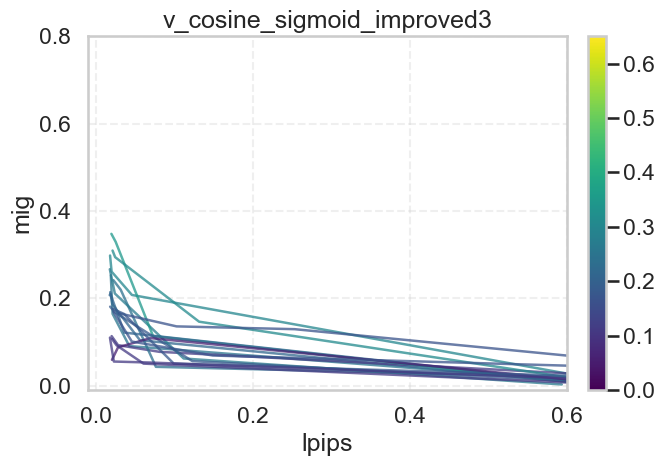

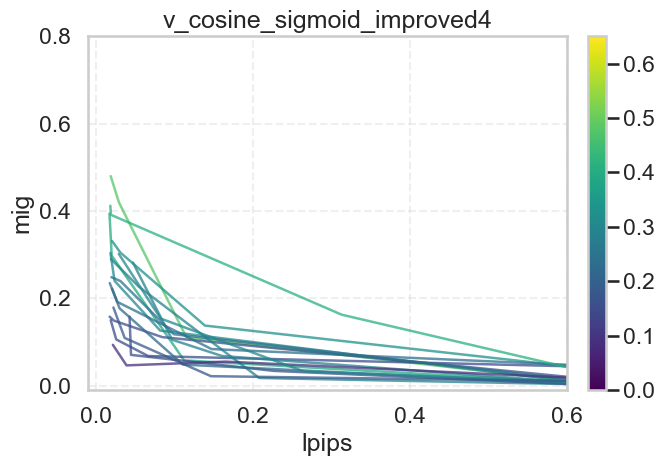

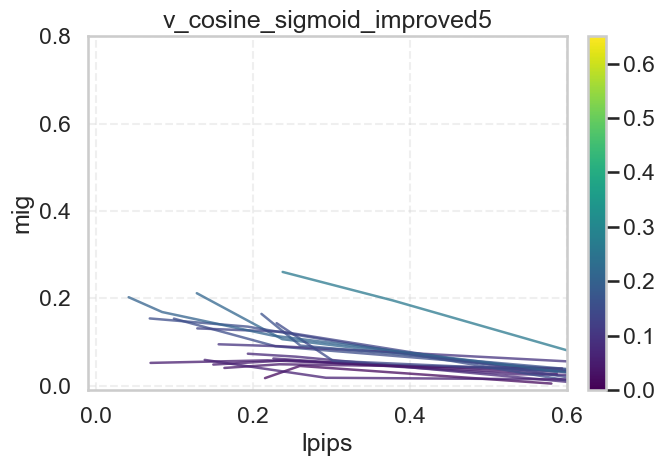

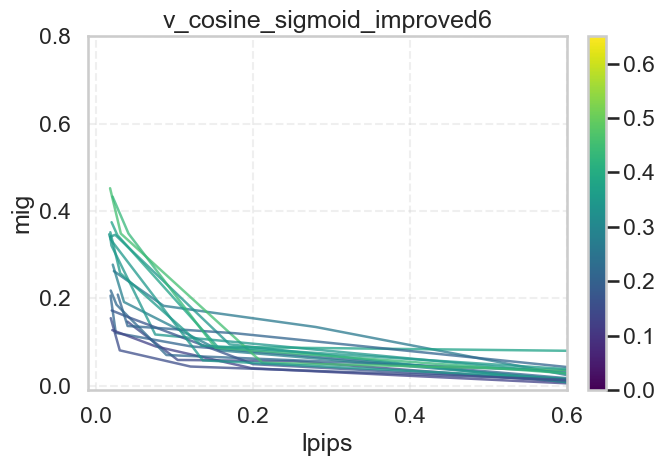

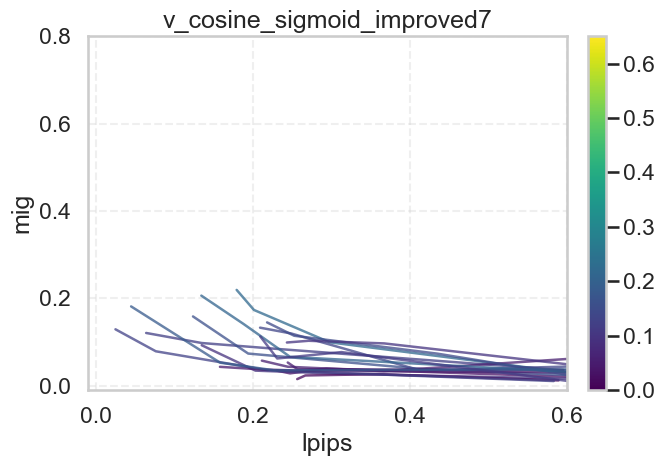

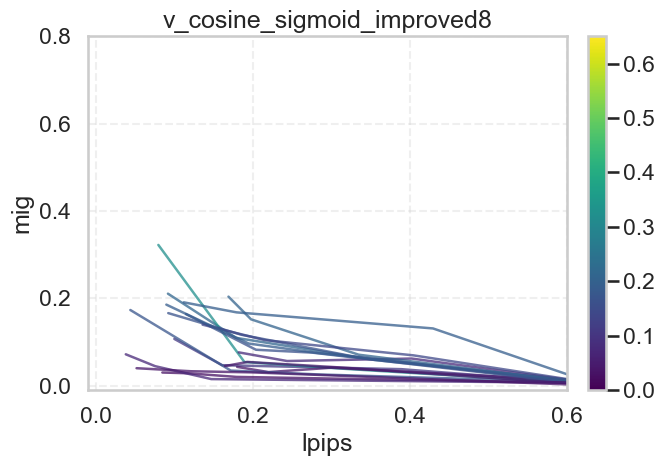

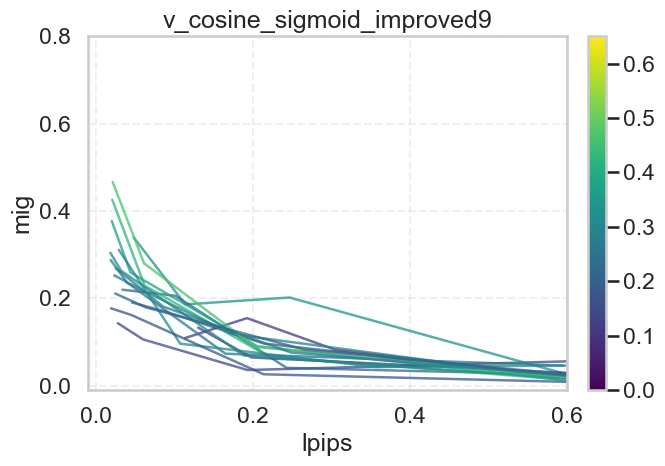

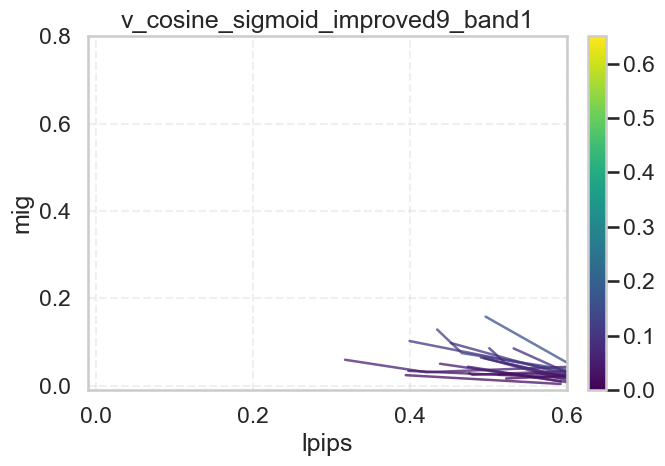

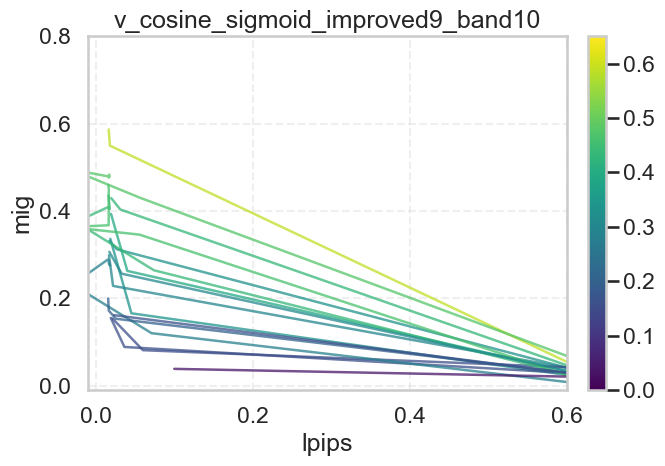

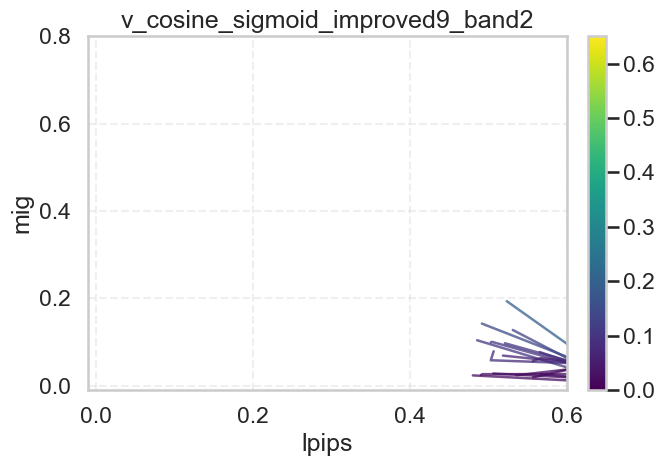

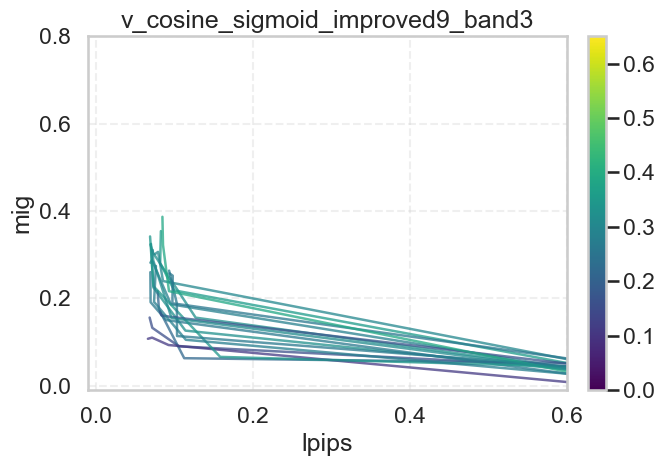

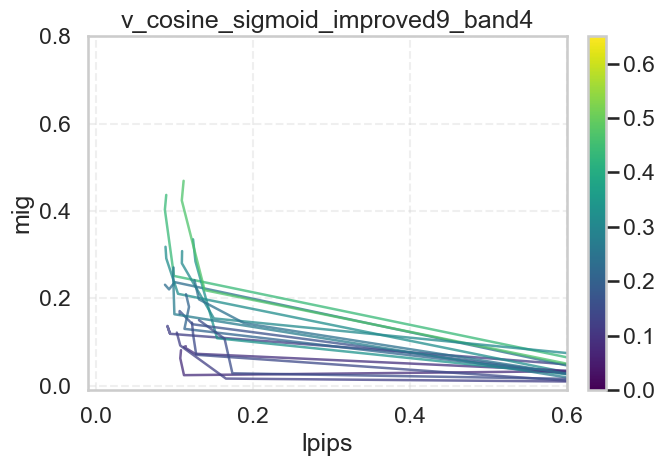

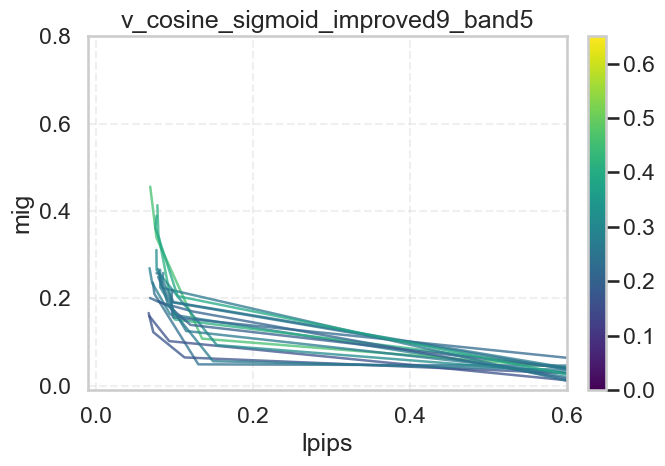

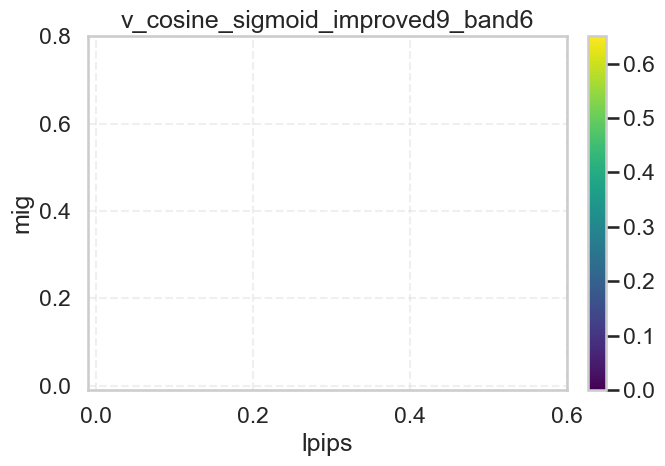

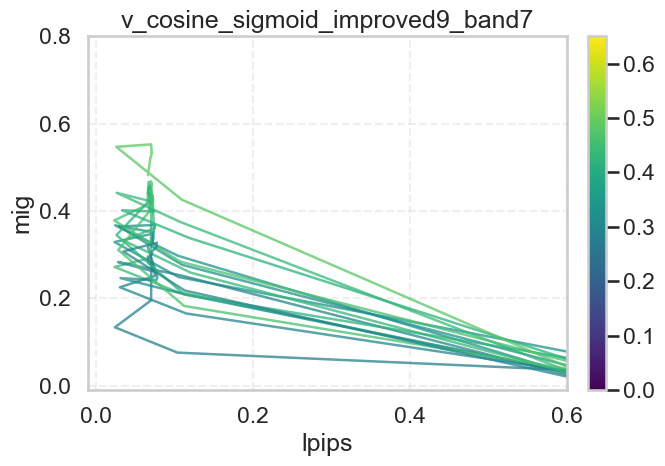

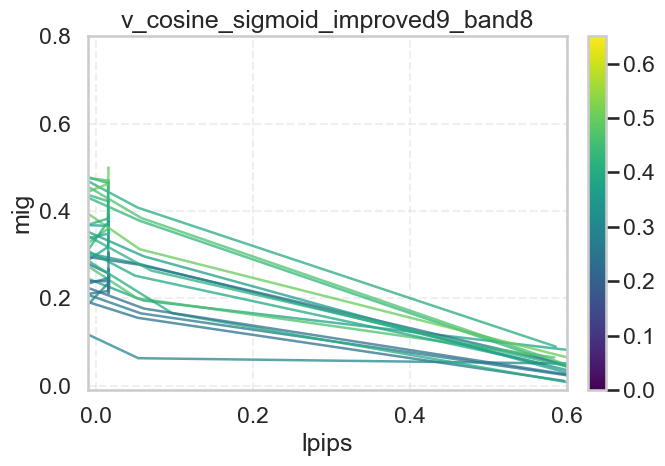

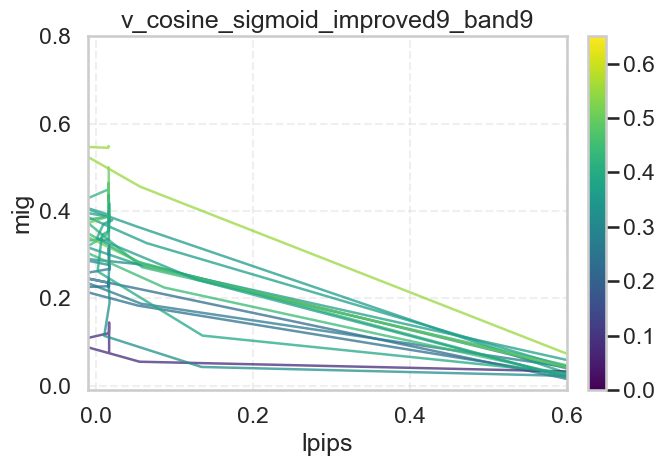

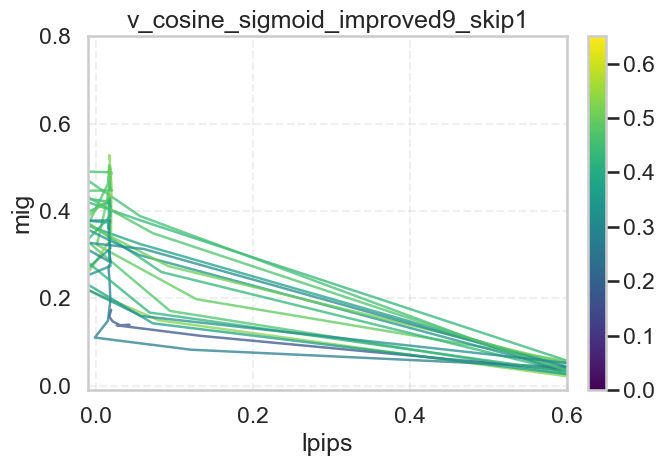

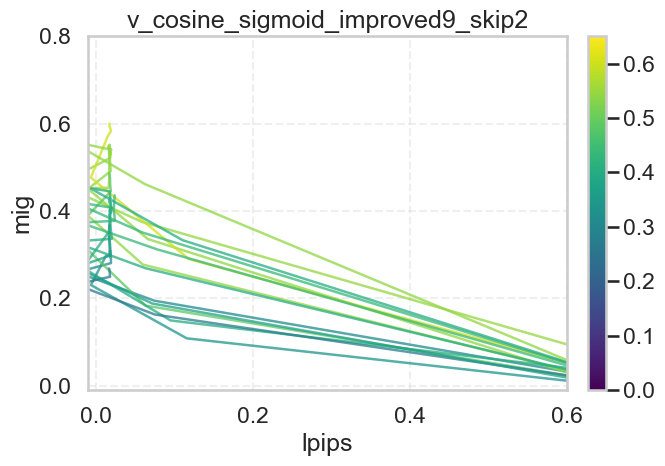

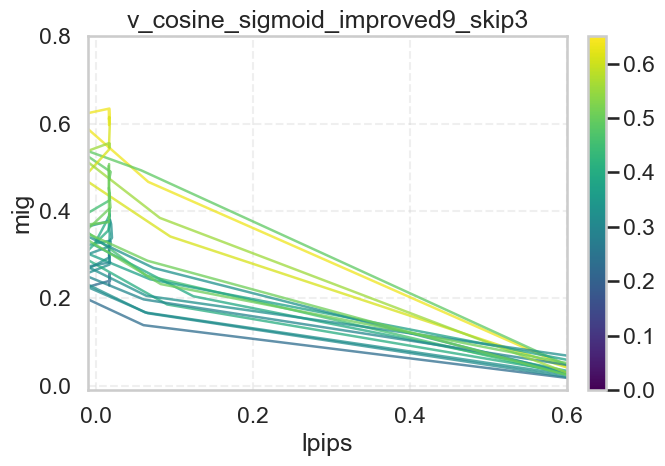

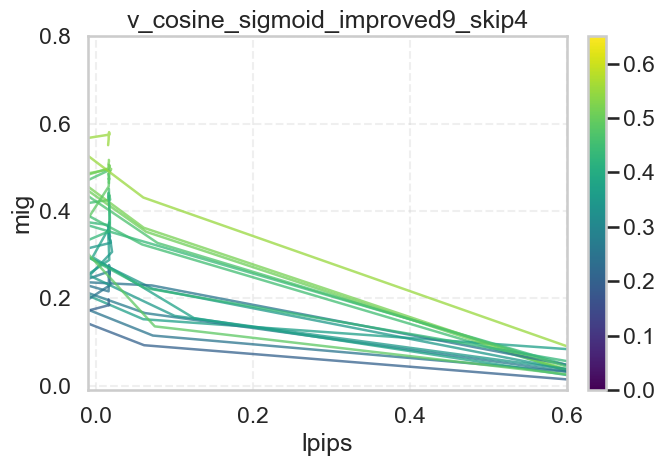

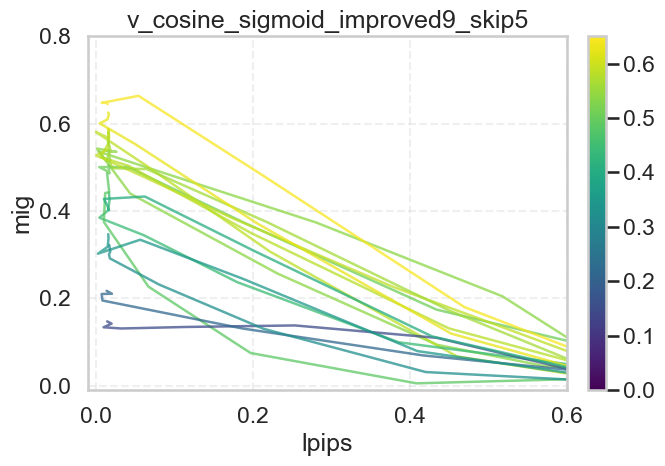

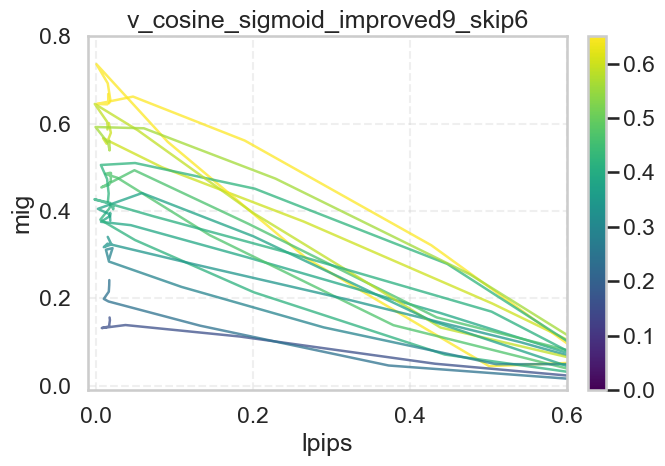

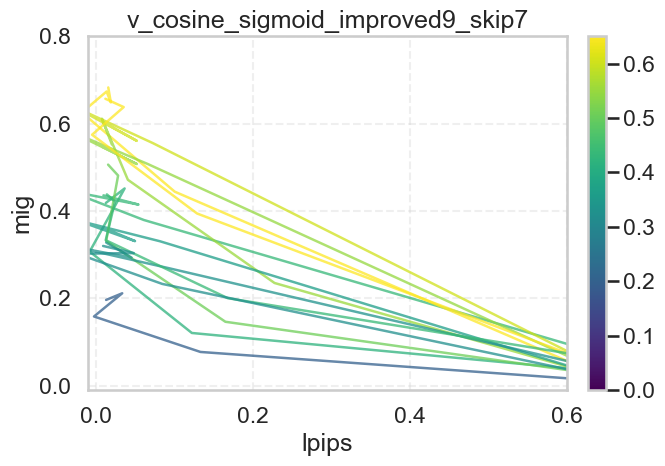

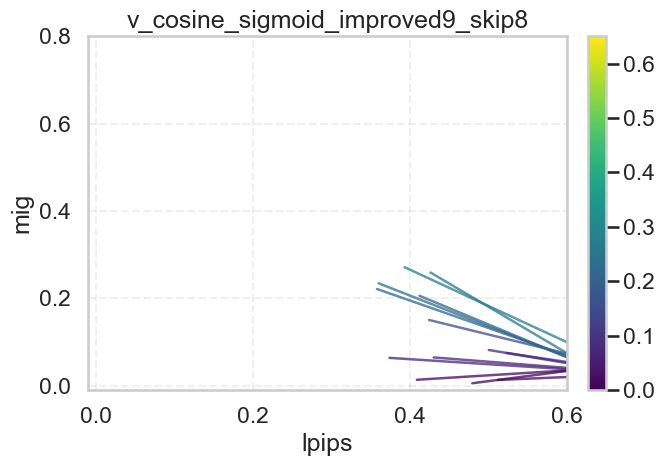

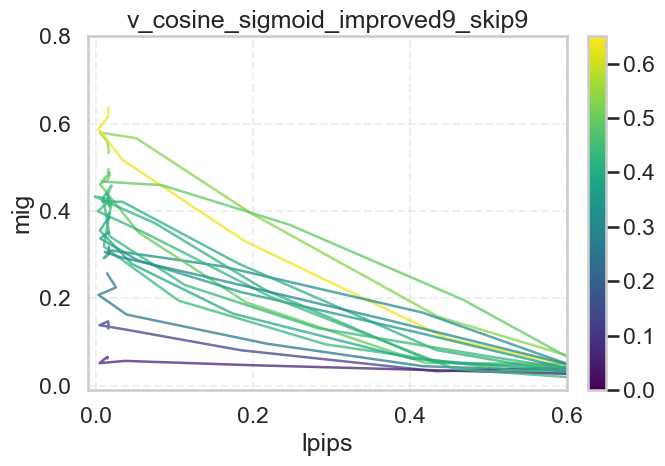

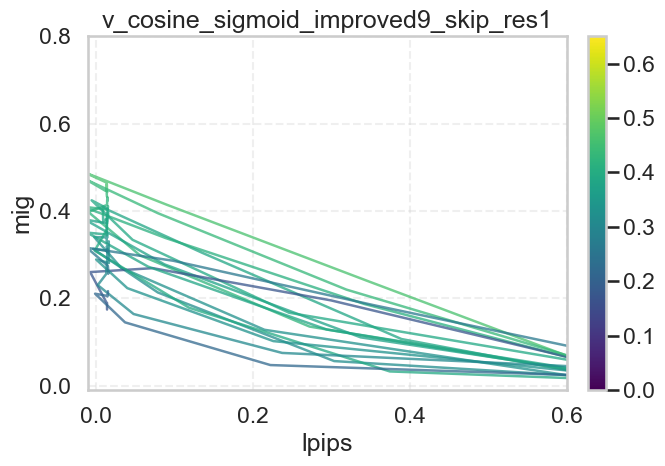

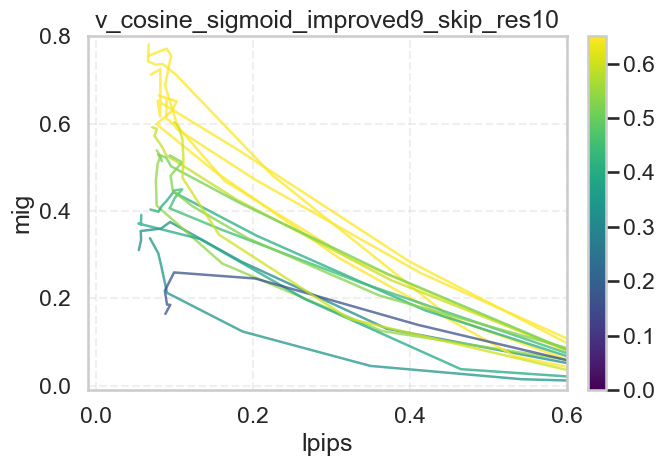

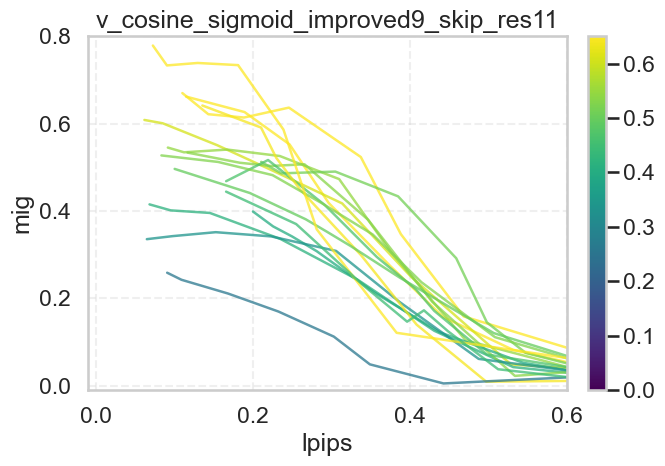

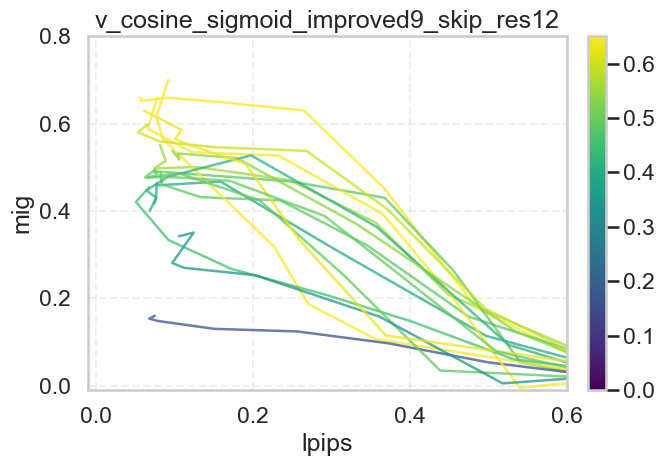

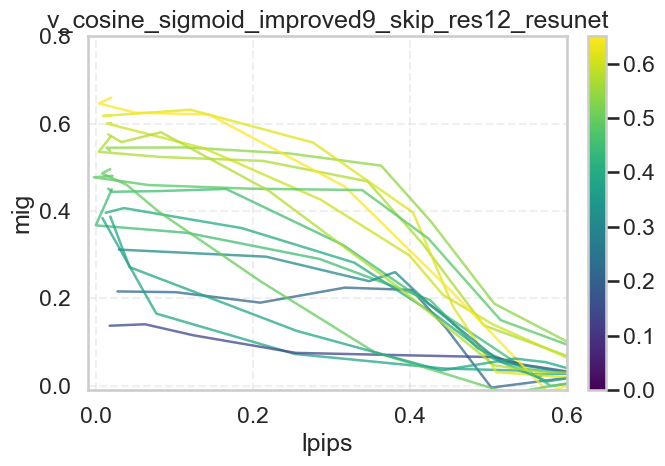

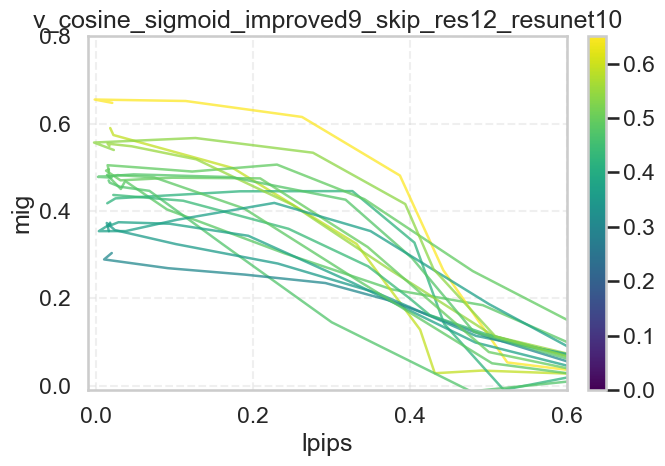

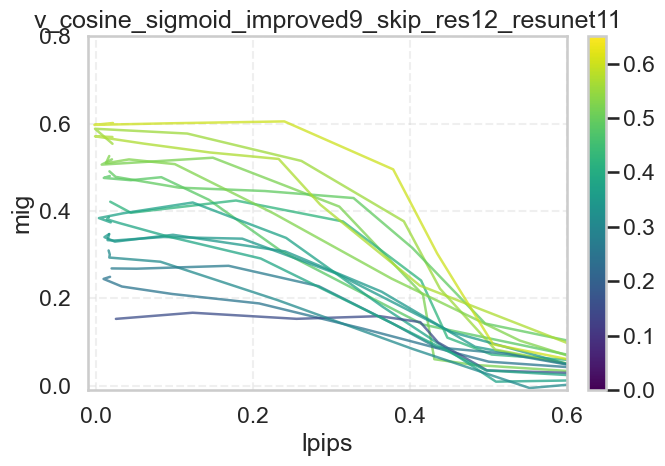

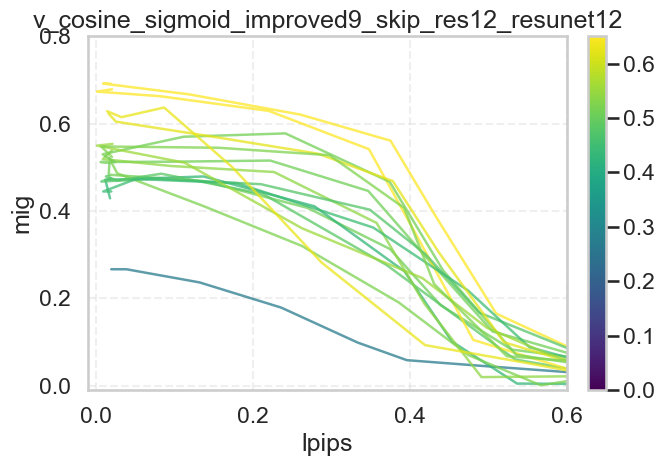

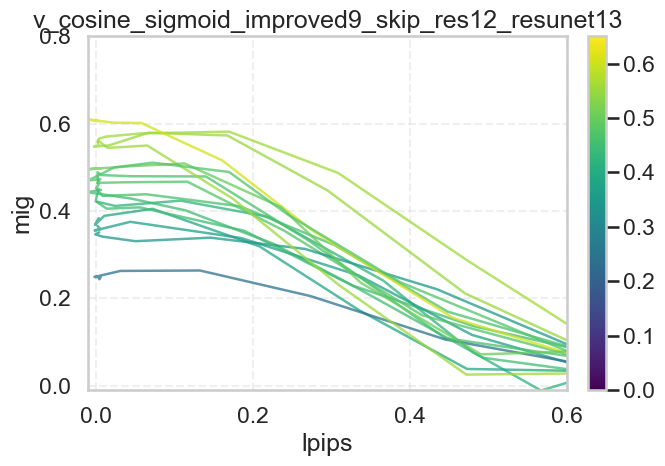

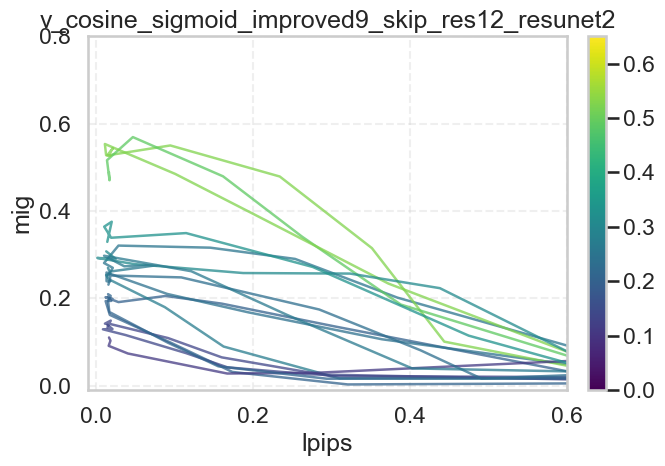

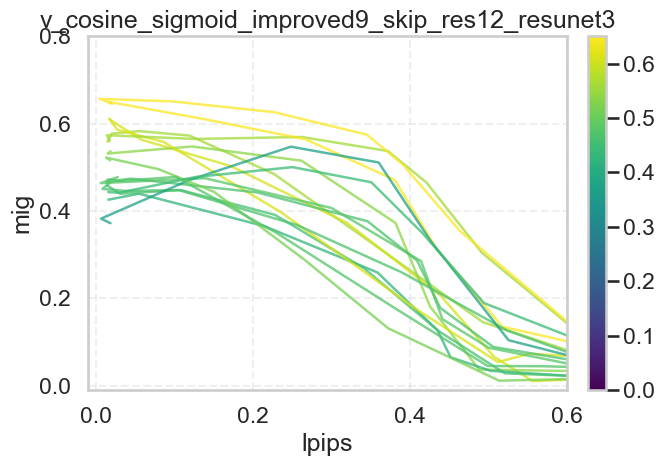

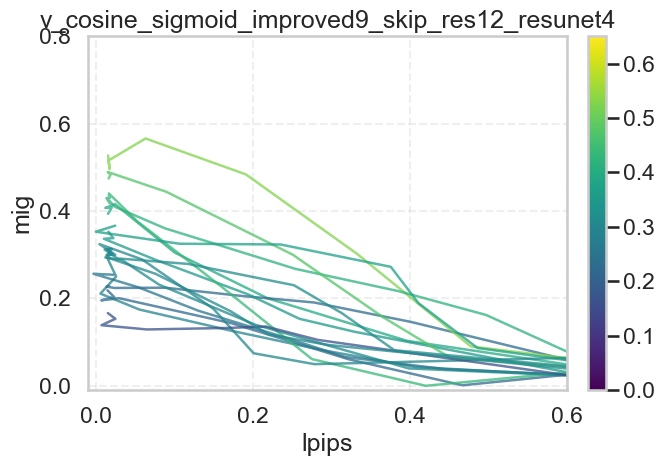

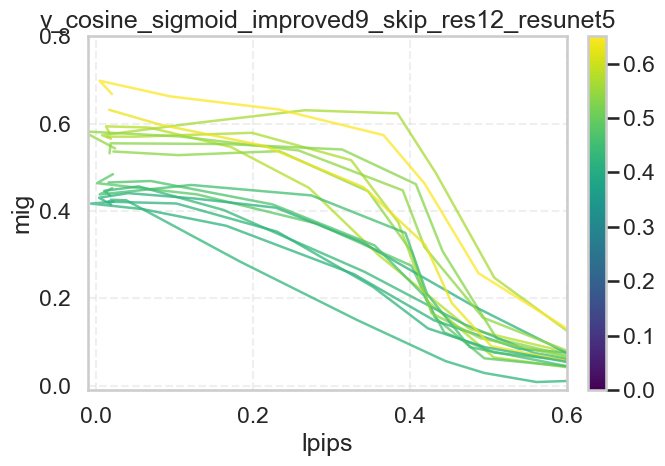

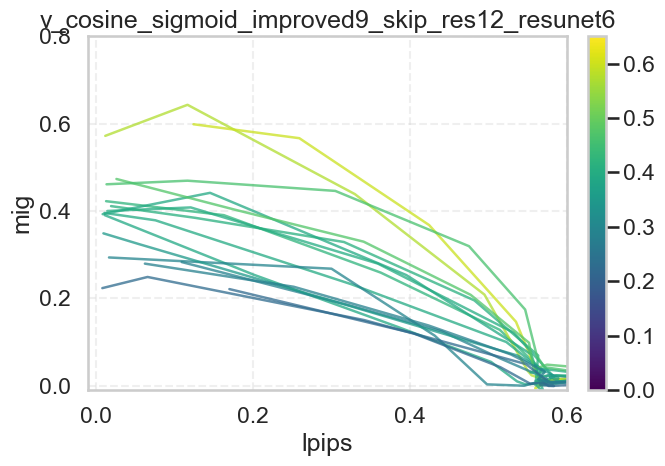

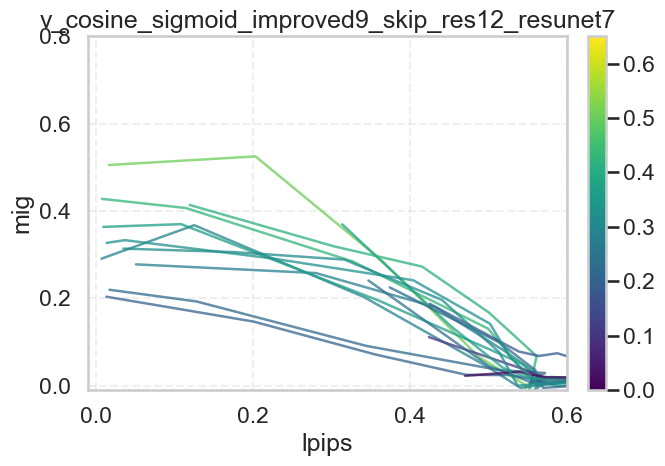

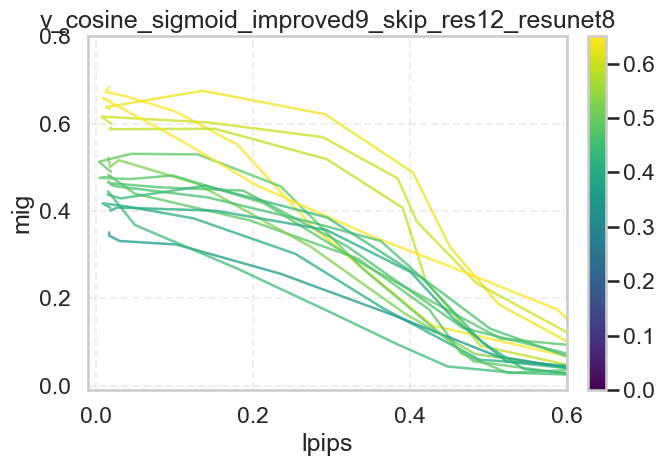

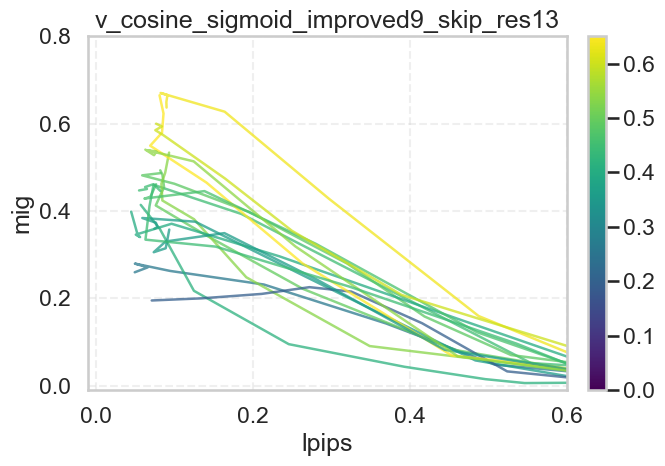

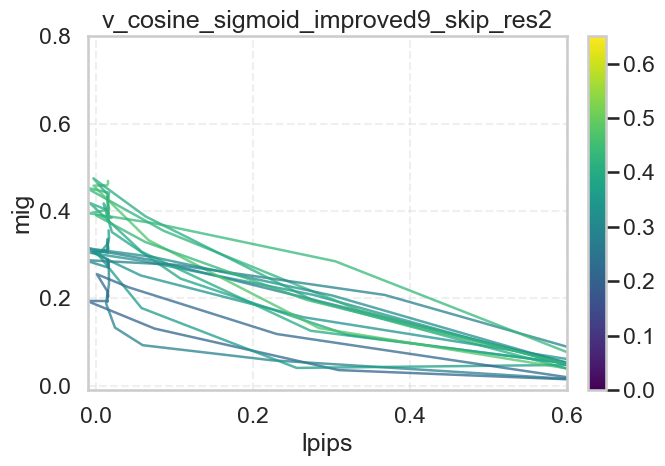

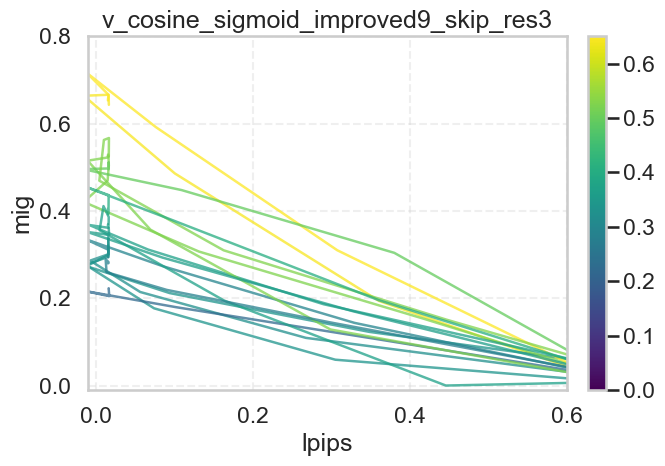

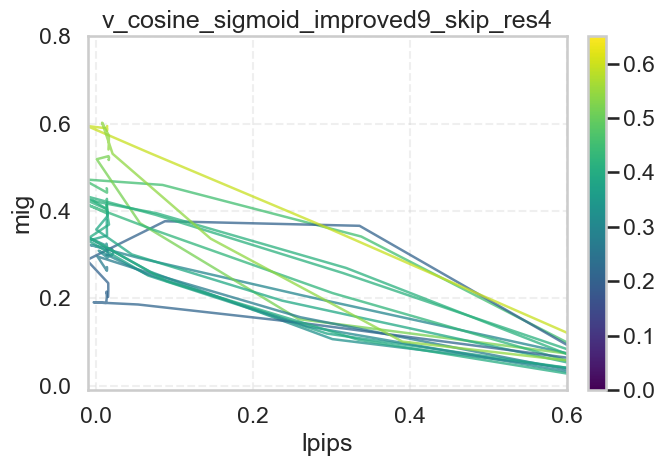

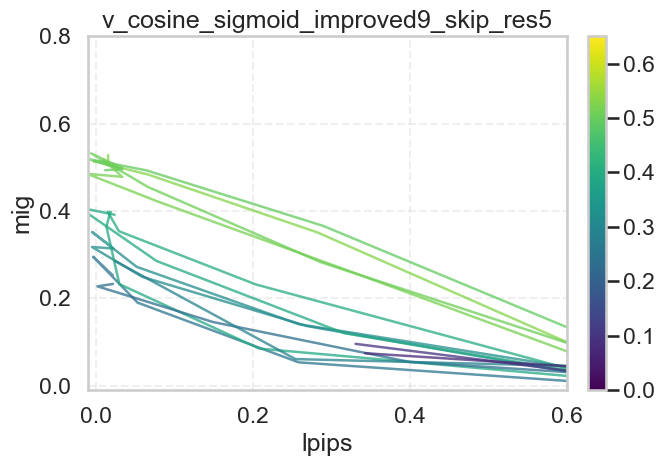

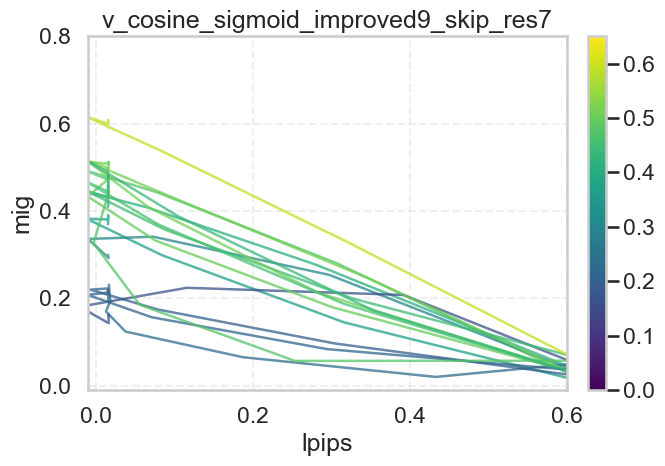

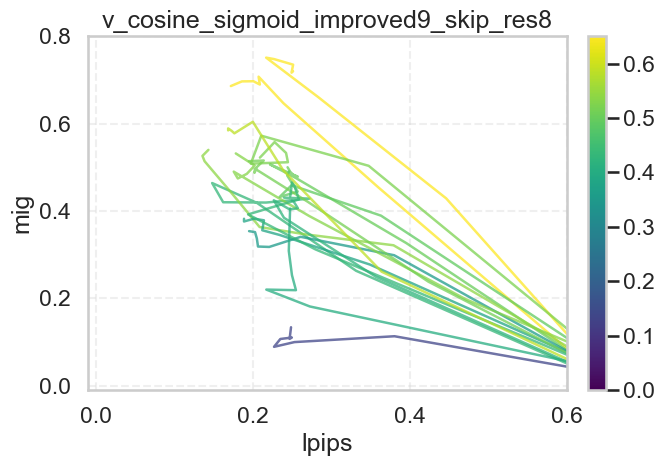

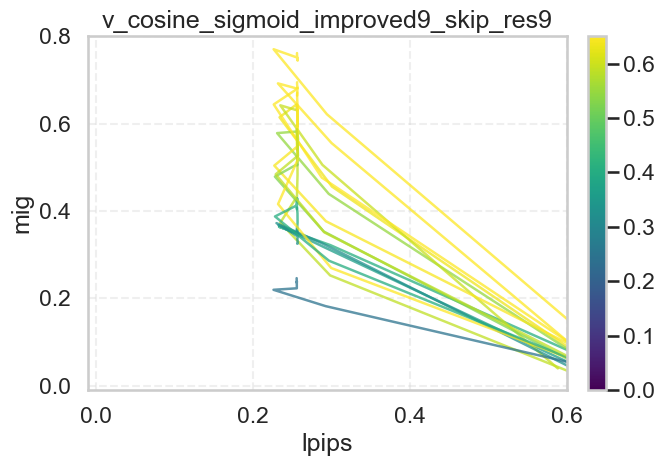

In [177]:
# ROOT = "ckpts/vdmpp/shapes3d_low_discrep..."
# ROOT = "ckpts/vdmpp/shapes3d_early_stage/..."

# ROOT = "ckpts/vdmpp_deep/shapes3d/"
# ROOT = "ckpts/vdmpp_deep_longer/shapes3d/"
# ROOT = "ckpts/vdmpp_deep_longer_stable/shapes3d/"

# ROOT = "ckpts/vdmpp_deep_longer_stable2/shapes3d/"
ROOT = "ckpts/vdmpp_deep_longer_stable2_improved/shapes3d/"

plot_dis_vs_recon_per_model_class(
    ROOT,
    dis_col="mig",
    lpips_col="lpips",
    out_dir="analysis_plots/dis_vs_recon_by_model",
    file_ext="pdf",
    show=True,
    overlay_mean=False,
    window=5,
    diff_order=0,
    figsize=(7, 5),
    max_nimgs=5120000,
    tail_smooth_after=1500000,
    tail_window=30,
    tail_poly=5,
)

In [18]:
def load_data(
    base_dir: str,
    dis_col: str = "dci",
    lpips_col: str = "lpips",
):
    """
    For each model class, generate ONE figure with two panels:
        (left)  dis vs mse
        (right) dis vs lpips

    Each seed/run is a trajectory line through checkpoints (nimgs).
    Line colour is determined by the run's FINAL disentanglement metric (dis_col),
    normalised WITHIN the model class (so colours are comparable within each figure).

    Optionally overlays the mean trajectory across seeds in black dashed.
    """
    run_dirs = [
        d for d in os.listdir(base_dir)
        if os.path.isdir(os.path.join(base_dir, d))
    ]
    run_dirs = sorted(run_dirs)
    if not run_dirs:
        raise RuntimeError(f"No run directories found in {base_dir}")

    # ---------- group runs by model_class ----------
    groups: Dict[str, List[str]] = {}
    seeds_by_run: Dict[str, Optional[int]] = {}
    for run_name in run_dirs:
        model_class, seed = parse_run_name_seedprefix(run_name)
        groups.setdefault(model_class, []).append(run_name)
        seeds_by_run[run_name] = seed

    # ---------- load metrics per run ----------
    per_run_df: Dict[str, pd.DataFrame] = {}
    per_run_debug = {}
    for run_name in run_dirs:
        metrics_path = os.path.join(base_dir, run_name, "metrics.csv")
        debug_path = os.path.join(base_dir, run_name, "debug.csv")
        if not os.path.exists(metrics_path):
            continue
        if not os.path.exists(debug_path):
            continue
        df = _safe_read_metrics(metrics_path)
        df_debug = _safe_read_metrics(debug_path)
        if df is None:
            continue
        if df_debug is None:
            continue
        per_run_df[run_name] = df
        per_run_debug[run_name] = df_debug

    return per_run_df, per_run_debug

In [47]:
import numpy as np
from scipy.optimize import curve_fit

def dynamics_model_to_plateau2(t, A, k):
    # increase to inf (plateau) if A > 0
    return A * (1 - np.exp(-k * t))

def fit_mig(t, metric):
    t = np.asarray(t, dtype=float)
    y = np.asarray(metric, dtype=float)

    # Basic cleaning
    mask = np.isfinite(t) & np.isfinite(y)
    t, y = t[mask], y[mask]
    if len(t) < 3:
        return {"A_mig": np.nan, "k_mig": np.nan, "r0": np.nan, "tau": np.nan}

    # Ensure t is nonnegative and increasing-ish (not required, but helps interpretation)
    # If your t is "nimgs", this is already true.
    t = t - t.min()

    # Initial guesses:
    # A: use late-training value (median of last 20%)
    tail = y[int(0.8 * len(y)):] if len(y) >= 5 else y
    A0 = float(np.clip(np.median(tail), 1e-6, np.inf))

    # k: roughly match early slope: y ≈ A*k*t for small t -> slope ≈ A*k
    # Estimate slope from first few points
    n_early = min(5, len(t))
    # protect against all t being identical
    if np.ptp(t[:n_early]) > 0:
        slope0 = np.polyfit(t[:n_early], y[:n_early], deg=1)[0]
        k0 = float(np.clip(slope0 / max(A0, 1e-6), 1e-6, np.inf))
    else:
        k0 = 1.0

    p0 = [A0, k0]
    bounds = ([0.0, 0.0], [np.inf, np.inf])

    popt, _ = curve_fit(
        dynamics_model_to_plateau2,
        t, y,
        p0=p0,
        bounds=bounds,
        maxfev=200000
    )

    A_hat, k_hat = popt
    return {
        "A_mig": float(A_hat),
        "k_mig": float(k_hat),
        "r0": float(A_hat * k_hat),     # initial slope at t=0
        "tau": float(1.0 / k_hat) if k_hat > 0 else np.inf,
    }

def fit_run(nimgs, lpips, mig, nimgs_max=9984000, nimgs_min=12800):
    t = (np.asarray(nimgs) - nimgs_min) / (nimgs_max - nimgs_min + 1e-12)
    t = np.clip(t, 0.0, 1.0)

    # lp = fit_lpips(t, lpips)
    mg = fit_mig(t, mig)
    return {**mg}

import numpy as np

def tail_median(x, frac=0.8):
    x = np.asarray(x, float)
    start = int(frac * len(x))
    return float(np.median(x[start:])) if len(x) >= 5 else float(np.median(x))

def ttc_threshold(nimgs, metric, thr, direction="le"):
    """Return first nimgs where metric crosses threshold."""
    nimgs = np.asarray(nimgs)
    metric = np.asarray(metric, float)
    if direction == "le":
        idx = np.where(metric <= thr)[0]
    else:
        idx = np.where(metric >= thr)[0]
    return float(nimgs[idx[0]]) if len(idx) else np.nan

def ttc_fraction_of_final(nimgs, metric, final_value, frac=0.8, increasing=True):
    """Time to reach y0 + frac*(final-y0) for increasing metrics, or analogous for decreasing."""
    nimgs = np.asarray(nimgs)
    metric = np.asarray(metric, float)
    y0 = float(metric[0])
    yf = float(final_value)

    if increasing:
        target = y0 + frac * (yf - y0)
        idx = np.where(metric >= target)[0]
    else:
        target = y0 - frac * (y0 - yf)
        idx = np.where(metric <= target)[0]

    return float(nimgs[idx[0]]) if len(idx) else np.nan

import os
import pandas as pd

def load_runs(root):
    per_run = {}
    for run in sorted(os.listdir(root)):
        run_dir = os.path.join(root, run)
        if not os.path.isdir(run_dir):
            continue
        csv_path = os.path.join(run_dir, "metrics.csv")
        if not os.path.exists(csv_path):
            continue
        df = pd.read_csv(csv_path)
        per_run[run] = df
    return per_run

def parse_run_name(run):
    parts = run.split("_")
    variant = parts[0]                       # e.g. "00A"
    weighting = "_".join(parts[1:]) if len(parts) > 1 else "base"
    return variant, weighting

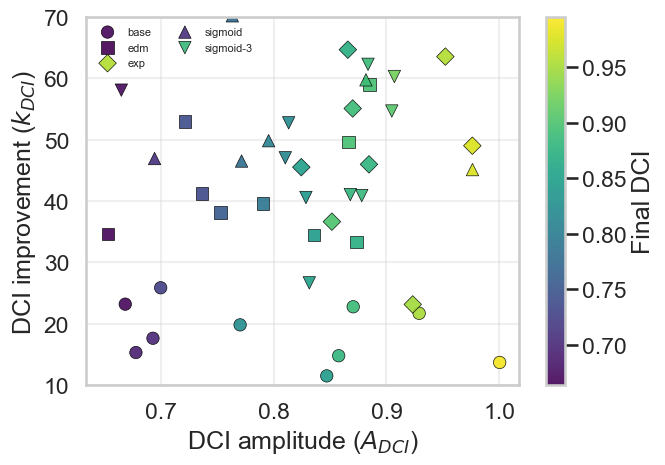

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "ckpts/final/shapes3d"
per_run = load_runs(ROOT)

all_coeffs = []

for run, metrics in per_run.items():
    variant, weighting = parse_run_name(run)
    if not ((variant.endswith("A") and weighting == "base") or weighting in ["edm", "exp", "sigmoid", "sigmoid-3"]):
        continue

    nimgs = metrics["nimgs"].values
    lpips = metrics["lpips"].values
    mig   = metrics["dci"].values

    # skip degenerate runs
    if len(mig) < 5 or not np.isfinite(mig).any():
        continue

    coeffs = fit_run(nimgs, lpips, mig)

    mig0 = float(np.nanmedian(mig[:max(1, int(0.1 * len(mig)))]))   # robust "start"
    mig_final = tail_median(mig, frac=0.8)

    coeffs.update({
        "run": run,
        "variant": variant,
        "weighting": weighting,
        "mig0": mig0,
        "mig_final": mig_final,
        "mig_improvement": float(mig_final - mig0),   # y-axis
        "mig_amplitude": float(coeffs["A_mig"]),      # x-axis (model fit)
        "lpips_final": tail_median(lpips, frac=0.8),
    })

    all_coeffs.append(coeffs)

df = pd.DataFrame(all_coeffs)

import matplotlib.pyplot as plt
import numpy as np

# Define marker per weighting
markers = {
    "base": "o",
    "edm": "s",
    "exp": "D",
    "sigmoid": "^",
    "sigmoid-3": "v",
    "sigmoid-5": "P",
}

cvals = df["mig_final"].values
vmin, vmax = np.min(cvals), np.max(cvals)

plt.figure(figsize=(7, 5))

for w, sub in df.groupby("weighting"):
    marker = markers.get(w, "o")
    
    sc = plt.scatter(
        sub["A_mig"],                # x: amplitude
        sub["k_mig"],      # y: improvement
        c=sub["mig_final"],          # color: final MIG
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        marker=marker,
        edgecolor="black",
        linewidth=0.5,
        s=80,
        alpha=0.9,
        label=w
    )

plt.xlabel("DCI amplitude ($A_{DCI}$)")
plt.ylabel("DCI improvement ($k_{DCI}$)")

cbar = plt.colorbar(sc)
cbar.set_label("Final DCI")
plt.ylim(10, 70)
# plt.xlim(0.65, 1)
plt.legend(frameon=False, fontsize=8, ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# ROOT = "ckpts/vdmpp_deep_longer_stable/shapes3d"
ROOT = "ckpts/final/shapes3d"

per_run_df, per_run_debug = load_data(ROOT, dis_col='mig')

all_coeffs = []

for run, metrics in per_run_df.items():
    if not (run.endswith("A") or any(run.endswith(model) for model in ["edm", "exp", "sigmoid"])):
        continue
        
    run_name = run.split("_")
    weighting = run_name[-1]
    
    nimgs = metrics.nimgs.values
    lpips = metrics.lpips.values
    mig = metrics.mig.values

    coeffs = fit_run(nimgs, lpips, mig)
    coeffs['mig_convergence'] = np.median(mig[int(0.8 * len(mig)):] if len(mig) >= 5 else mig)
    coeffs['lpips_convergence'] = np.median(lpips[int(0.8 * len(lpips)):] if len(lpips) >= 5 else lpips)
    coeffs['weighting'] = weighting
    coeffs['run_name'] = run_name[0]
    
    # debug_df = per_run_debug[run]
    # coeffs['grads_ratio'] = (debug_df[debug_df.nimgs < 200000].window_enc_mean / debug_df[debug_df.nimgs < 200000].window_dec_mean).mean()
    # mask = (debug_df.nimgs >= 50000) & (debug_df.nimgs < 200000)
    # coeffs['grads_enc'] = debug_df[mask].window_enc_mean.mean()

    coeffs["mig_final"] = tail_median(mig)
    coeffs["lpips_final"] = tail_median(lpips)
    
    coeffs["ttc_lpips"] = ttc_threshold(nimgs, lpips, thr=0.03, direction="le")
    coeffs["ttc_mig"]   = ttc_fraction_of_final(nimgs, mig, final_value=coeffs["mig_final"], frac=0.8, increasing=True)
    
    all_coeffs.append(coeffs)

df = pd.DataFrame(all_coeffs)

In [36]:
import pandas as pd
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

marker = {
    'edm': 'o',
    'exp': '^',
    'sigmoid': 'P',
    'sech': 'p',
}
titles = {
    'k_lpips': 'LPIPS Improvement Rate',
    'k_mig': 'MIG Improvement Rate',
    'A_lpips': 'LPIPS Amplitude',
    'A_mig': 'MIG Amplitude',
    'ttc_lpips': 'LPIPS Time to Converge',
    'ttc_mig': 'MIG Time to Converge',
    'tau': 'Characteristic Timescale',
    'r0': 'Early Improvement Rate',
}
lims = {
    'k_lpips': (5, 200), # (5, 110),
    'k_mig': (-2, 27), # (-2, 25),
    'A_lpips': (0.4, 0.60),
    'A_mig': (0, 0.65),
    'ttc_lpips': (0, 3500000),
    'ttc_mig': (0, 4000000),
    'tau': (0, 0.3),
    'r0': (0, 20),
}

# def size3_from_lpips(lp, q=(0.33, 0.66), sizes=(120, 260, 520), invert=True):
#     """
#     3-band size mapping.
#     invert=True => smaller LPIPS -> larger marker (usually what you want).
#     """
#     lp = np.asarray(lp, float)
#     q1, q2 = np.nanquantile(lp, q)

#     # bins: 0 (low), 1 (mid), 2 (high)
#     bins = np.digitize(lp, [q1, q2])  # returns 0,1,2

#     if invert:
#         bins = 2 - bins  # low LPIPS -> bin 2 -> largest size

#     return np.array(sizes, dtype=float)[bins]]

from matplotlib.colors import TwoSlopeNorm

def plot_coeffs(df, x, y, c="mig", cmap="viridis"):
    for weighting, _df in df.groupby('weighting'):
        print(weighting)
        if c == "mig":
            c_series = _df.mig_convergence
            c_label = "MIG @ Convergence"
            norm = None
        elif c == "lpips":
            c_series = _df.lpips_convergence
            c_label = "LPIPS @ Convergence"
            norm = None
        elif "grads" in c:
            c_series = _df[c]
            c_label = "Early Gradients"
            norm = None #TwoSlopeNorm(vmin=0.04, vcenter=0.055, vmax=0.08)
            
        plt.scatter(
            _df[x],
            _df[y],
            c=c_series,
            # s=sizes,
            marker=marker[weighting],
            label=weighting,
            cmap=cmap,
            norm=norm,
            alpha=0.9,
        )
    
    plt.xlabel(titles[x])
    plt.ylabel(titles[y])
    plt.colorbar(label=c_label)
    plt.xlim(left=lims[x][0], right=lims[x][1])
    plt.ylim(bottom=lims[y][0], top=lims[y][1])
    
    handles = [
        Line2D([0], [0],
               marker=marker[w], linestyle="None",
               markerfacecolor="black", markeredgecolor="black",
               color="black", markersize=8, label=w)
        for w in marker
    ]
    plt.legend(handles=handles, title="$w(\lambda)$", fontsize=10, title_fontsize=10)
    plt.tight_layout()
    plt.savefig(f"characterising_{x}_{y}.pdf")
    plt.show()


# plot_coeffs(df, 'A_mig', 'A_lpips', "mig")
# plot_coeffs(df, 'k_lpips', 'A_mig', "lpips")
# plot_coeffs(df, 'A_lpips', 'k_lpips', "mig")
# plot_coeffs(df, 'A_mig', 'k_mig', "lpips")
# plot_coeffs(df, 'A_mig', 'k_mig', "lpips")
# plot_coeffs(df, 'A_lpips', 'k_lpips', "mig")
# plot_coeffs(df, 'A_lpips', 'k_lpips', c="lpips", cmap="viridis")
# plot_coeffs(df, 'A_mig', 'k_mig', c="lpips", cmap="magma")
# plot_coeffs(df, 'A_mig', 'k_mig', c="grads_enc", cmap="coolwarm")

# plot_coeffs(df, 'ttc_mig', 'ttc_lpips', c="mig", cmap="viridis")
plot_coeffs(df, 'k_lpips', 'k_mig', "mig")
# plot_coeffs(df, 'A_mig', 'A_lpips', c="mig", cmap="viridis")
plot_coeffs(df, 'A_mig', 'k_mig', c="mig", cmap="viridis")
plot_coeffs(df, 'A_lpips', 'k_lpips', c="mig", cmap="viridis")
# plot_coeffs(df, 'tau', 'r0', c="mig", cmap="viridis")

00A


KeyError: '00A'

In [8]:
ROOT = "ckpts/vdmpp_deep_longer_stable2_improved/shapes3d/"
per_run_df, _ = load_data(ROOT)
# model = "cosine_sigmoid_improved6"

# model = "cosine_sigmoid_improved9"
# model = "cosine_exp_improved9"
# model = "cosine_sech_improved9"

# model = "cosine_sigmoid_improved9_band8"

# model = "cosine_sigmoid_improved9_skip5"
# model = "cosine_sigmoid_improved3"
# model = "cosine_sigmoid_improved9_skip3"
# model = "cosine_sigmoid_improved9_skip9"

# model = "cosine_sigmoid_improved9_skip_res8"
# model = "cosine_sigmoid_improved9_skip_res9"

# model = "cosine_sigmoid_improved9_skip_res10"
# model = "cosine_sigmoid_improved9_skip_res11"
# model = "cosine_sigmoid_improved9_skip_res13"

# model = "cosine_sigmoid_improved9_skip_res12"
# model = "cosine_sigmoid_improved9_skip_res12_resunet"
# model = "cosine_sigmoid_improved9_skip_res12_resunet3"
# model = "cosine_sigmoid_improved9_skip_res12_resunet8"
# model = "cosine_sigmoid_improved9_skip_res12_resunet10"

# model = "cosine_sigmoid_improved9_skip_res12_resunet12"
model = "cosine_sigmoid_improved9_skip_res12_resunet13"

ROOT = "ckpts/final/cars3d/"
ROOT = "ckpts/final/mpi3d/"
per_run_df, _ = load_data(ROOT)
model = "I"

fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20, 5))

for i, (metric, bottom, top) in enumerate([("factorvae", 0.4, 1.0), ("dci", 0., 1.), ("mig", 0, 0.7), ("lpips", 0, 0.7)]):
    for k, v in per_run_df.items():
        if not k.endswith(model):
            continue
        x = per_run_df[k]['nimgs']
        y = per_run_df[k][metric]
        # if metric == "lpips":
        #     print(y.values[-1])
        # if metric == "factorvae" or metric == "lpips":
        # print("model seed:", k[0], "timestep seed:", k[1], f"{metric}: {y.values}")
        axes[i].set_title(metric)
        axes[i].set_ylim(bottom=bottom, top=top)
        axes[i].plot(x.values, y.values) #, label=k[:2])

# fig.suptitle("$\lambda \in [-5, 12]$, band widening start $\lambda \in [0, 10]$ over 64K steps")
# fig.suptitle("$\lambda \in [-15, 15]$, band widening start $\lambda \in [0, 10]$ over 32K steps")
# fig.suptitle("$\lambda \in [-5, 12]$, band widening start $\lambda \in [0, 10]$ over 32K steps")
# fig.suptitle("$\lambda \in [-15, 15]$, band widening start $\lambda \in [0, 10]$ over 64K steps")
plt.show()

NameError: name 'parse_run_name_seedprefix' is not defined

In [9]:
# fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

# for i, (metric, bottom, top) in enumerate([("factorvae", 0.8, 1.05), ("dci", 0.75, 1.05), ("mig", 0.1, 0.75)]):
#     for k, v in per_run_df.items():
#         if not k.endswith(model):
#             continue
#         y = per_run_df[k]['lpips']
#         x = per_run_df[k][metric]
#         axes[i].set_xlabel(metric)
#         axes[i].scatter(x.values[-1], y.values[-1])
#     if i != 0:
#         axes[i].set_yticklabels([])
#     if i == 0:
#         axes[i].set_ylabel('lpips')
#     # axes[i].set_ylim(bottom=0.017, top=0.023)

# plt.show()

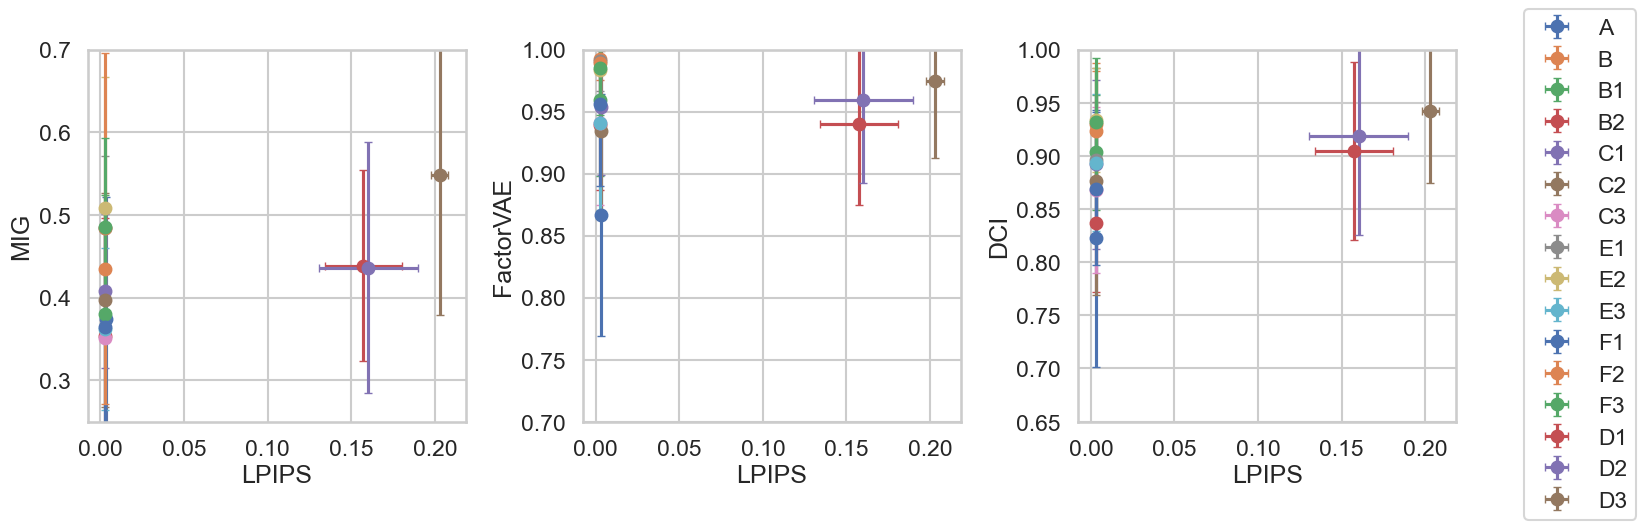

In [12]:
from collections import defaultdict

# ROOT = "ckpts/vdmpp_deep_longer_stable2_improved/shapes3d/"
# per_run_df, _ = load_data(ROOT)
# ROOT2 = "ckpts/vdmpp_deep_longer_stable/shapes3d"
# per_run_df2, _ = load_data(ROOT2)

# # models = [
# #     ("cosine_sech", "baseline"),
# #     ("cosine_sigmoid_improved9_band9", "deep2 + AdaLN-zero"),
# #     ("cosine_sigmoid_improved9_skip4", "skip dropout"),
# #     ("cosine_sigmoid_improved9_skip5", "skip dropout + band widening"),
# #     ("cosine_sigmoid_improved9_skip_res8", "no skip conn."),
# #     ("cosine_sigmoid_improved9_skip_res9", "no skip conn. + rezero"),
# #     ("cosine_sigmoid_improved9_skip_res12_resunet3", "skip add"),
# #     ("cosine_sigmoid_improved9_skip_res12_resunet12", "skip add + softplus residuals"),
# # ]
# models = [
#     ("cosine_sech", "A"),
#     ("cosine_sigmoid_improved9_band9", "B"),
#     ("cosine_sigmoid_improved9_skip4", "C"),
#     ("cosine_sigmoid_improved9_skip5", "D"),
#     ("cosine_sigmoid_improved9_skip_res8", "E"),
#     ("cosine_sigmoid_improved9_skip_res9", "F"),
#     ("cosine_sigmoid_improved9_skip_res12_resunet3", "G"),
#     ("cosine_sigmoid_improved9_skip_res12_resunet12", "H1"),
# ]

# per_run_df_agg = defaultdict(lambda: defaultdict(list))

# for k, v in {**per_run_df, **per_run_df2}.items():
#     per_run_df_agg[k[4:]]["mig"].append(v.mig.values[-1])
#     per_run_df_agg[k[4:]]["fv"].append(v.factorvae.values[-1])
#     per_run_df_agg[k[4:]]["dci"].append(v.dci.values[-1])
#     per_run_df_agg[k[4:]]["lpips"].append(v.lpips.values[-1])

ROOT = "ckpts/final/shapes3d/"

# ROOT = "ckpts/final/cars3d/"
# per_run_df, _ = load_data(ROOT)

# ROOT = "ckpts/final/mpi3d/"
per_run_df, _ = load_data(ROOT)

models = [
    ("A", "A"),
    
    ("B", "B"),
    ("B1", "B1"),
    ("B2", "B2"),
    
    # Skip Dropout
    ("C", "C1"),
    ("D", "C2"),
    ("D1", "C3"),

    # Residual Skip
    ("G1", "E1"),
    ("G", "E2"),
    ("H", "E3"),

    # Gated Residual Skip
    ("I2", "F1"),
    ("I1", "F2"),
    ("I", "F3"),

    # Removed Skip
    ("E1", "D1"),
    ("E", "D2"),
    ("F", "D3"),
]

per_run_df_agg = defaultdict(lambda: defaultdict(list))

for k, v in per_run_df.items():
    per_run_df_agg[k[2:]]["mig"].append(v.mig.values[-1])
    per_run_df_agg[k[2:]]["fv"].append(v.factorvae.values[-1])
    per_run_df_agg[k[2:]]["dci"].append(v.dci.values[-1])
    per_run_df_agg[k[2:]]["lpips"].append(v.lpips.values[-1])

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

axes[0].set_ylabel("MIG")
axes[1].set_ylabel("FactorVAE")
axes[2].set_ylabel("DCI")
axes[0].set_xlabel("LPIPS")
axes[1].set_xlabel("LPIPS")
axes[2].set_xlabel("LPIPS")

axes[0].set_ylim(bottom=0.25, top=0.7)
axes[1].set_ylim(bottom=0.7, top=1.0)
axes[2].set_ylim(bottom=0.65, top=1.0)

for m, label in models:
    if m not in per_run_df_agg:
        continue

    # x stats (shared across all three plots)
    x = np.mean(per_run_df_agg[m]["lpips"])
    xerr = np.std(per_run_df_agg[m]["lpips"], ddof=1)

    # y stats per metric
    y_mig = np.mean(per_run_df_agg[m]["mig"])
    yerr_mig = np.std(per_run_df_agg[m]["mig"], ddof=1)

    y_fv = np.mean(per_run_df_agg[m]["fv"])
    yerr_fv = np.std(per_run_df_agg[m]["fv"], ddof=1)

    y_dci = np.mean(per_run_df_agg[m]["dci"])
    yerr_dci = np.std(per_run_df_agg[m]["dci"], ddof=1)

    # Plot mean point + error bars (use fmt='o' to show a marker)
    axes[0].errorbar(x, y_mig, xerr=xerr, yerr=yerr_mig, fmt='o', capsize=3, label=label)
    axes[1].errorbar(x, y_fv,  xerr=xerr, yerr=yerr_fv,  fmt='o', capsize=3, label=label)
    axes[2].errorbar(x, y_dci, xerr=xerr, yerr=yerr_dci, fmt='o', capsize=3, label=label)

# Get current legend entries (from first axis)
handles, labels = axes[0].get_legend_handles_labels()

# Map label -> handle
label_to_handle = {lab: h for h, lab in zip(handles, labels)}

# Desired order by your models list (using the human-readable label)
ordered_labels = []
ordered_handles = []
seen = set()

for _, lab in models:
    if lab in label_to_handle and lab not in seen:
        ordered_labels.append(lab)
        ordered_handles.append(label_to_handle[lab])
        seen.add(lab)

# Apply ordered legend (use one legend for the whole figure)
fig.legend(
    ordered_handles,
    ordered_labels,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)

# plt.legend()
plt.tight_layout()
plt.show()

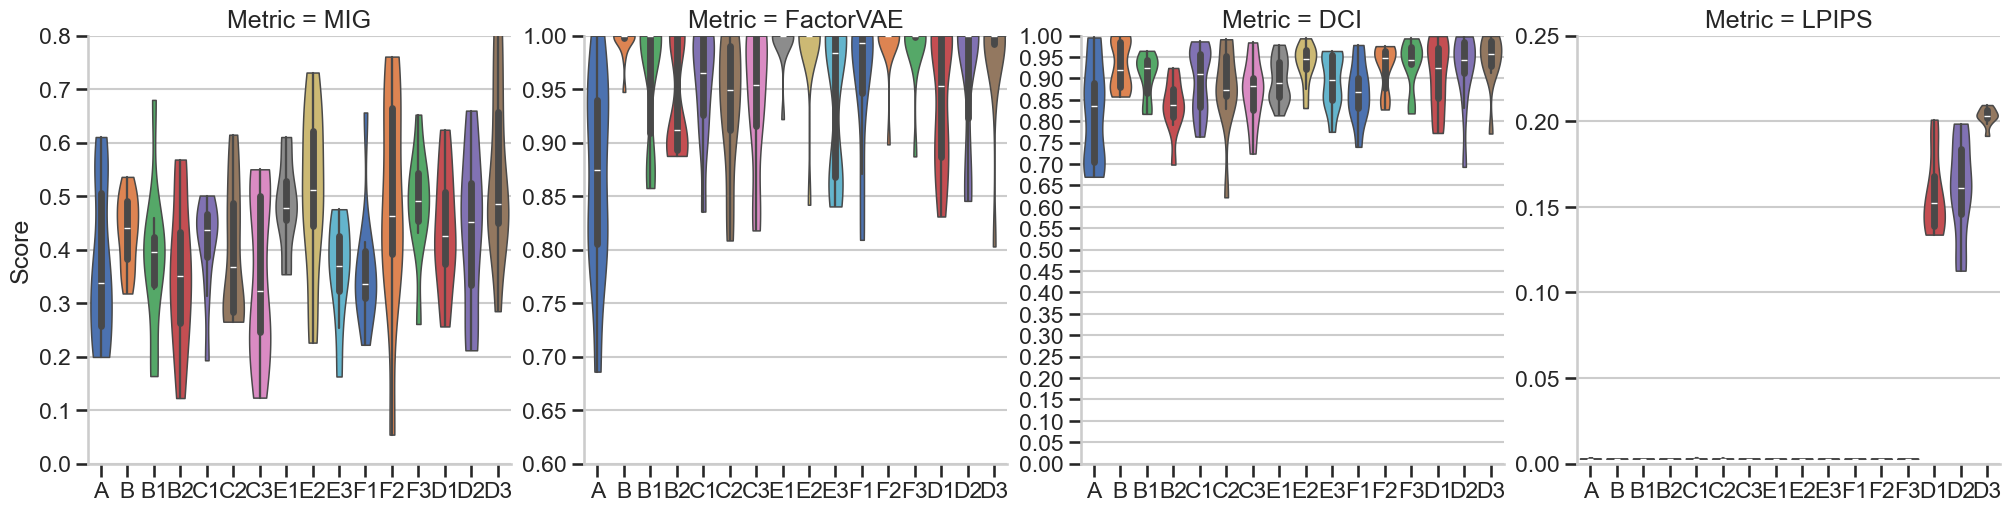

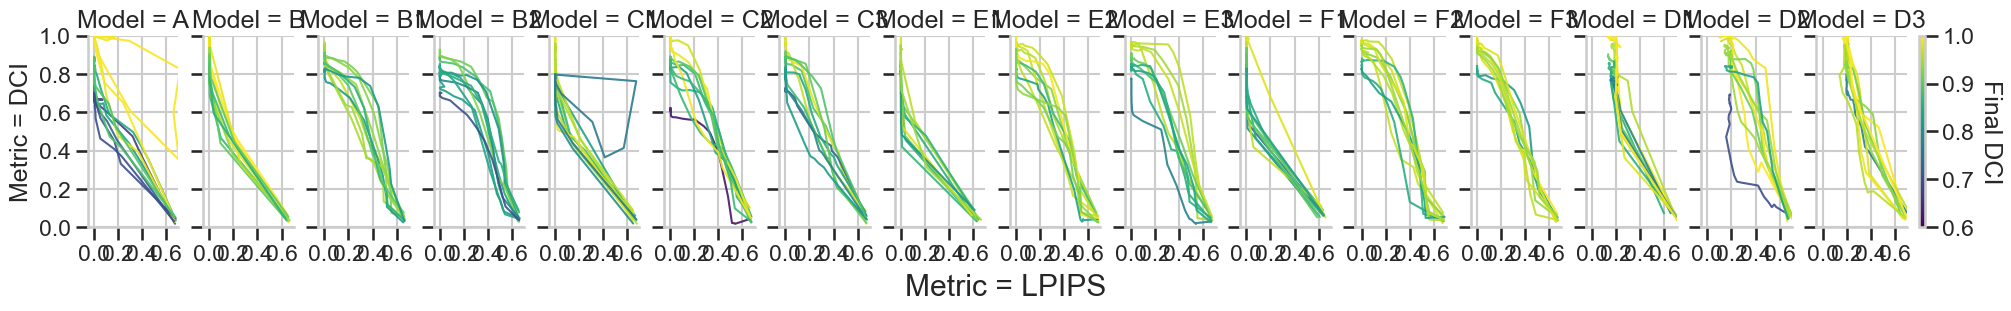

In [13]:
import matplotlib.ticker as mticker

fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20, 5), constrained_layout=True)

axes[0].set_title("Metric = MIG")
axes[1].set_title("Metric = FactorVAE")
axes[2].set_title("Metric = DCI")
axes[3].set_title("Metric = LPIPS")

axes[0].set_ylim(bottom=0, top=0.8)
axes[1].set_ylim(bottom=0.60, top=1.0)
axes[2].set_ylim(bottom=0.0, top=1.0)
axes[3].set_ylim(bottom=0, top=1.0)

model_order = [b for a, b in models]
palette = dict(zip(model_order, sns.color_palette(n_colors=len(model_order))))

for i, metric in enumerate(["mig", "fv", "dci", "lpips"]):
    rows = []
    for model, name in models:
        for val in per_run_df_agg[model][metric]:
            rows.append({"model": name, "value": val})
    df_plot = pd.DataFrame(rows)

    sns.violinplot(
        data=df_plot,
        x="model",
        y="value",
        order=model_order,
        hue="model",              # colour by model
        hue_order=model_order,
        palette=palette,
        dodge=False,              # don't split / offset
        inner="box",              # inner band/box
        cut=0,                    # don't extend beyond min/max
        bw_adjust=0.75,
        linewidth=1.1,
        saturation=1.0,
        ax=axes[i],
        legend=False,
    )

    axes[i].set_xlabel("")

    if metric in ["fv", "dci"]:
        axes[i].yaxis.set_major_locator(mticker.MultipleLocator(0.05))
    elif metric == "mig":
        axes[i].yaxis.set_major_locator(mticker.MultipleLocator(0.1))
    
    axes[i].tick_params(axis="y", left=True)
    axes[i].tick_params(axis="x", bottom=True)
    
    if i == 0:
        axes[i].set_ylabel("Score")
    else:
        axes[i].set_ylabel("")

    if metric == "lpips":
        axes[i].set_ylim(bottom=0.0, top=0.25)

    axes[i].spines["top"].set_visible(False)
    axes[i].spines["right"].set_visible(False)

# fig.supxlabel("Model")
# plt.tight_layout()
plt.savefig("dis_violins.pdf")
plt.show()

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.cm as cm

# 8 plot axes + 1 colorbar axis
fig, axes = plt.subplots(
    nrows=1,
    ncols=len(models) + 1,
    figsize=(20, 3),
    gridspec_kw={"width_ratios": len(models) * [1] + [0.06]},
    constrained_layout=True,
)

plot_axes = axes[:-1]
cax = axes[-1]

cmap_name = "viridis"
metric = "DCI"

norm = plt.Normalize(vmin=0.6, vmax=1.0)
cmap = plt.get_cmap(cmap_name)

for i, (model, name) in enumerate(models):
    ax = plot_axes[i]

    ax.set_title(f"Model = {name}")
    ax.set_xlim(-0.05, 0.7)
    ax.set_ylim(0., 1.0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.2))
    ax.xaxis.set_major_locator(mticker.MultipleLocator(0.2))
    ax.tick_params(axis="y", left=True)
    ax.tick_params(axis="x", bottom=True)

    if i == 0:
        ax.set_ylabel(f"Metric = {metric}")
    if i != 0:
        ax.set_yticklabels([])
    ax.set_xlabel("")

    for k, v in {**per_run_df}.items(): #, **per_run_df2}.items():
        if k.endswith(model):
            ax.plot(
                v.lpips,
                v.dci,
                c=cmap(norm(v.dci.values[-1])),
                linewidth=1.5,
                alpha=0.9,
            )

# Create colorbar in the dedicated axis
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Final DCI", rotation=270, labelpad=20)
cbar.ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))

fig.supxlabel("Metric = LPIPS")
plt.savefig("recon_vs_dis.pdf")
plt.show()

dci
model
A     0.8223 ± 0.1207
B     0.9299 ± 0.0576
C1    0.9046 ± 0.0834
C2    0.9190 ± 0.0936
C3    0.9420 ± 0.0671
D1    0.8692 ± 0.0722
D2    0.9238 ± 0.0564
D3    0.9316 ± 0.0607
dtype: object
lpips
model
A     0.0031 ± 0.0003
B     0.0029 ± 0.0000
C1    0.1573 ± 0.0232
C2    0.1602 ± 0.0295
C3    0.2029 ± 0.0052
D1    0.0029 ± 0.0001
D2    0.0029 ± 0.0000
D3    0.0029 ± 0.0001
dtype: object


/tmp/ipykernel_279892/1183454615.py:71: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df_plot.groupby("model").apply(agg))
/tmp/ipykernel_279892/1183454615.py:71: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df_plot.groupby("model").apply(agg))


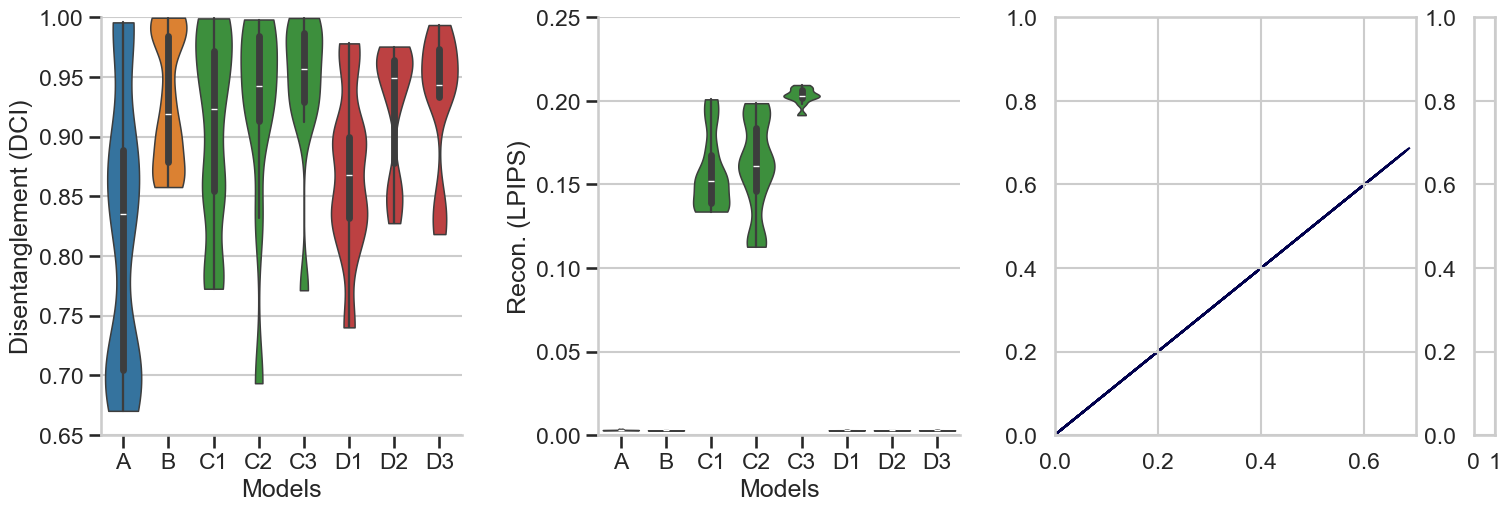

In [14]:
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

metrics_to_plot = [("dci", 0.65, 1.0), ("lpips", 0, 1.0)]

fig, axes = plt.subplots(
    nrows=1,
    ncols=6,
    figsize=(15, 5),
    constrained_layout=True,
    gridspec_kw={
        "width_ratios": [1, 0.08, 1, 0.08, 1, 0.06],
    },
)

axes[1].axis("off")
axes[3].axis("off")

models = [
    ("A", "A"),

    ("B", "B"),
    # ("B1", "B1"),
    # ("B2", "B2"),
    
    # Skip Dropout
    # ("C", "C1"),
    # ("D", "C2"),
    # ("D1", "C3"),

    # Removed Skip
    ("E1", "C1"),
    ("E", "C2"),
    ("F", "C3"),
    
    # Residual Skip
    # ("G1", "E1"),
    # ("G", "E2"),
    # ("H", "E3"),

    # Gated Residual Skip
    ("I2", "D1"),
    ("I1", "D2"),
    ("I", "D3"),
]

model_order = [b for a, b in models]

def group_letter(model_name: str) -> str:
    return model_name[0]

groups = sorted({group_letter(n) for n in model_order})
group_colors = dict(zip(groups, sns.color_palette("tab10", n_colors=len(groups))))
palette = {n: group_colors[group_letter(n)] for n in model_order}

def agg(group):
    return f"{group.value.mean():.4f} ± {group.value.std():.4f}"

# metric = "dci"

for i, (metric, lb, ub) in zip([0, 2], metrics_to_plot):
    axes[i].set_ylim(bottom=lb, top=ub)
    
    rows = []
    for model, name in models:
        for val in per_run_df_agg[model][metric]:
            rows.append({"model": name, "value": val})
    df_plot = pd.DataFrame(rows)

    print(metric)
    print(df_plot.groupby("model").apply(agg))
    # print()

    sns.violinplot(
        data=df_plot,
        x="model",
        y="value",
        order=model_order,
        hue="model",              # colour by model
        hue_order=model_order,
        palette=palette,
        dodge=False,              # don't split / offset
        inner="box",              # inner band/box
        cut=0,                    # don't extend beyond min/max
        bw_adjust=0.5,
        linewidth=1.1,
        saturation=0.7,
        ax=axes[i],
        legend=False,
    )

    axes[i].set_xlabel("Models")

    if metric in ["fv", "dci"]:
        axes[i].yaxis.set_major_locator(mticker.MultipleLocator(0.05))
    elif metric == "mig":
        axes[i].yaxis.set_major_locator(mticker.MultipleLocator(0.1))
    
    axes[i].tick_params(axis="y", left=True)
    axes[i].tick_params(axis="x", bottom=True)
    
    if metric == "lpips":
        axes[i].set_ylim(bottom=0.0, top=0.25)
        axes[i].set_ylabel(f"Recon. (LPIPS)")
    else:
        axes[i].set_ylabel(f"Disentanglement ({metric.upper()})")

    axes[i].spines["top"].set_visible(False)
    axes[i].spines["right"].set_visible(False)

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.cm as cm

plot_axes = axes[-2]
cax = axes[-1]

plot_axes.set_xlim(0., 0.7)
plot_axes.set_ylim(0., 1.0)

# cmap_name = "viridis"
cmap_name = "seismic"
cmap = plt.get_cmap(cmap_name)
norm = plt.Normalize(vmin=0.7, vmax=1.0)
# import matplotlib.colors as mcolors

# norm = mcolors.TwoSlopeNorm(
#     vmin=0.7,      # worst DCI
#     vcenter=0.92,   # your chosen midpoint
#     vmax=1.0       # best DCI
# )

linestyles = {
    # "A": "-",
    # "E1": "-",
    # "E2": "--",
    "D1": "-",
    "D2": "--",
    "D3": ":",
}

def smooth_curve(y, window=9, poly=3):
    """Savitzky–Golay smoothing with safe window handling."""
    n = len(y)
    if n < 3:
        return y
    w = min(window, n if n % 2 == 1 else n - 1)
    if w < 3:
        return y
    return savgol_filter(y, window_length=w, polyorder=min(poly, w - 1))

# collect all trajectories first
trajectories = []

for (model, name) in models:
    if name not in linestyles:
        continue

    for k, v in per_run_df.items():
        if k.endswith(model):
            xs = v.lpips.values
            ys = v[metric].values

            final_dci = ys[-1:].mean()

            trajectories.append({
                "xs": xs,
                "ys": ys,
                "name": name,
                "final_dci": final_dci,
            })

# sort by final DCI (lowest first, highest last)
trajectories = sorted(trajectories, key=lambda d: d["final_dci"])

# now plot in sorted order
for traj in trajectories:
    # if len(traj["xs"]) < 10:
    #     continue
    # else:
    #     # print(len(traj["xs"]))
    if traj["name"] == "D1":
        linewidth = 0.5 + 1.2 * (1 - norm(traj["final_dci"]))
    else:
        linewidth = 0.5 + 1.2 * norm(traj["final_dci"])
    plot_axes.plot(
        traj["xs"],
        traj["ys"], # smooth_curve(traj["ys"]),
        c=cmap(norm(traj["final_dci"])),
        linewidth=1.5,
        alpha=1,
        # alpha = 0.5 + 0.5 * norm(traj["final_dci"]),
        linestyle=linestyles[traj["name"]],
        # linewidth=linewidth, #1.0 + 1.2 * norm(traj["final_dci"]),
        zorder=traj["final_dci"],  # optional extra safety
    )

# legend_handles = [
#     Line2D([0], [0], color="black", lw=1.8, linestyle="-"),
#     Line2D([0], [0], color="black", lw=1.8, linestyle="--"),
#     Line2D([0], [0], color="black", lw=1.8, linestyle=":"),
# ]

# # legend_labels = [
# #     "E1 & F1",
# #     "E2 & F3",
# # ]
# legend_labels = [
#     "D1",
#     "D2",
#     "D3",
# ]

# plot_axes.legend(
#     legend_handles,
#     legend_labels,
#     # title="Skip strategy",
#     loc="upper right",
#     frameon=True,
# )

# plot_axes.set_xlabel("Recon. (LPIPS)")
# plot_axes.set_ylabel("Disentanglement (DCI)")
# plot_axes.tick_params(axis="y", left=True)
# plot_axes.tick_params(axis="x", bottom=True)
# plot_axes.spines["top"].set_visible(False)
# plot_axes.spines["right"].set_visible(False)

# # Create colorbar in the dedicated axis
# sm = cm.ScalarMappable(norm=norm, cmap=cmap)
# sm.set_array([])

# cbar = fig.colorbar(sm, cax=cax)
# cbar.set_label("Final DCI", rotation=270, labelpad=20)
# cbar.ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))

plt.savefig("recon_vs_dis.pdf")
plt.show()

Aside from the baseline, all models use our improved deeper encoder with a deep feature extractor, FiLM-style features, and AdaLN-Zero normalisation for cross-attention conditioning, and the sigmoid weighting function. To condition the models on $\lambda$ as opposed to $t$, our models use a learnable Fourier encoding for the logsnr as opposed to the fixed sin-cos embedding.

| Model | Our Encoder + Conditioning | Skip Strategy        | Band-Widening | Gated Cross-Attn. Residuals |
|-------|----------------------------|----------------------|---------------|-----------------------------|
| A     | ❌                         | Concat               | ❌            | ❌                          |
| B     | ✅                         | Concat               | ❌            | ❌                          |
| B3    | ✅                         | Concat               | ✅            | ❌                          |
| B4    | ✅                         | Concat               | ✅            | ✅                          |
| C1    | ✅                         | Skip Dropout (0.5)   | ❌            | ❌                          |
| C2    | ✅                         | Skip Dropout (0.5)   | ✅            | ❌                          |
| C1    | ✅                         | Skip Dropout (0.5)   | ✅            | ✅                          |
| D1    | ✅                         | Removed Skip         | ❌            | ❌                          |
| D2    | ✅                         | Removed Skip         | ✅            | ❌                          |
| D3    | ✅                         | Removed Skip         | ✅            | ✅                          |
| E1    | ✅                         | Residual Skip        | ❌            | ❌                          |
| E2    | ✅                         | Residual Skip        | ✅            | ❌                          |
| E3    | ✅                         | Residual Skip        | ✅            | ✅                          |
| F1    | ✅                         | Gated Residual Skip  | ❌            | ❌                          |
| F2    | ✅                         | Gated Residual Skip  | ✅            | ❌                          |
| F3    | ✅                         | Gated Residual Skip  | ✅            | ✅                          |

| B1    | ✅                         | Constant Scaling     | ❌            | ❌                          |
| B2    | ✅                         | Power Scaling        | ❌            | ❌                          |

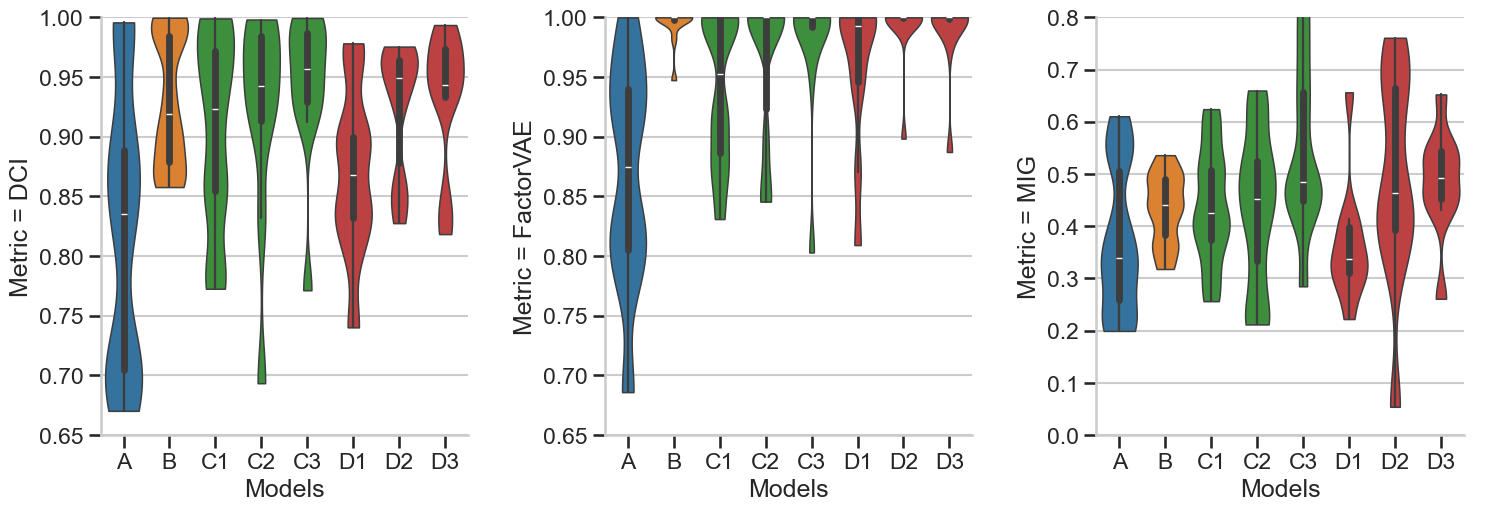

In [52]:
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

metrics_to_plot = [("dci", 0.65, 1.0), ("fv", 0.65, 1.0), ("mig", 0.0, 0.8)] #, ("lpips", 0, 1.0)]

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(metrics_to_plot) * 2,
    figsize=(5 * len(metrics_to_plot), 5),
    constrained_layout=True,
    gridspec_kw={
        "width_ratios": [1, 0.08] * len(metrics_to_plot), # , 1, 0.08, 1, 0.06],
    },
)

# axes.axis("off")

models = [
    ("A", "A"),

    ("B", "B"),
    # ("B1", "B1"),
    # ("B2", "B2"),
    
    # Skip Dropout
    # ("C", "C1"),
    # ("D", "C2"),
    # ("D1", "C3"),

    # Removed Skip
    ("E1", "C1"),
    ("E", "C2"),
    ("F", "C3"),
    
    # Residual Skip
    # ("G1", "E1"),
    # ("G", "E2"),
    # ("H", "E3"),

    # Gated Residual Skip
    ("I2", "D1"),
    ("I1", "D2"),
    ("I", "D3"),
]

model_order = [b for a, b in models]

def group_letter(model_name: str) -> str:
    return model_name[0]

groups = sorted({group_letter(n) for n in model_order})
group_colors = dict(zip(groups, sns.color_palette("tab10", n_colors=len(groups))))
palette = {n: group_colors[group_letter(n)] for n in model_order}

def agg(group):
    return f"{group.value.mean():.4f} ± {group.value.std():.4f}"

for i, (metric, lb, ub) in zip([0, 2, 4], metrics_to_plot):
    axes[i + 1].axis("off")
    axes[i].set_ylim(bottom=lb, top=ub)
    
    rows = []
    for model, name in models:
        for val in per_run_df_agg[model][metric]:
            rows.append({"model": name, "value": val})
    df_plot = pd.DataFrame(rows)

    sns.violinplot(
        data=df_plot,
        x="model",
        y="value",
        order=model_order,
        hue="model",              # colour by model
        hue_order=model_order,
        palette=palette,
        dodge=False,              # don't split / offset
        inner="box",              # inner band/box
        cut=0,                    # don't extend beyond min/max
        bw_adjust=0.5,
        linewidth=1.1,
        saturation=0.7,
        ax=axes[i],
        legend=False,
    )

    axes[i].set_xlabel("Models")

    if metric in ["fv", "dci"]:
        axes[i].yaxis.set_major_locator(mticker.MultipleLocator(0.05))
    elif metric == "mig":
        axes[i].yaxis.set_major_locator(mticker.MultipleLocator(0.1))
    
    axes[i].tick_params(axis="y", left=True)
    axes[i].tick_params(axis="x", bottom=True)
    
    if metric == "lpips":
        axes[i].set_ylim(bottom=0.0, top=0.25)
        axes[i].set_ylabel(f"Recon. (LPIPS)")
    else:
        axes[i].set_ylabel(f"Metric = {metric.upper() if metric in ['dci', 'mig'] else 'FactorVAE'}")

    axes[i].spines["top"].set_visible(False)
    axes[i].spines["right"].set_visible(False)

plt.savefig("dis_metrics.pdf")
plt.show()

In [ ]:
# Final runs, model B with BW + GR
# Train EncDiff baseline 10 times + Add that to the plot of the other weighting functions. I can use this in my motivation/analysis section.
# Once this is done, on the best config, compare the different weighting functions again?
# Put a huge ablation table in the Appendix.

# Compare interventions on timesteps vs (BW + Gated Residuals)
# Compared Gated Residual Skip vs Residual Skip

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.cm as cm

# 8 plot axes + 1 colorbar axis
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(5, 5),
    gridspec_kw={"width_ratios": [1, 0.06]},
    constrained_layout=True,
)

axes[0].set_xlim(-0.05, 0.7)
axes[0].set_ylim(0., 1.0)

plot_axes = axes[0]
cax = axes[1]

cmap_name = "viridis"
norm = plt.Normalize(vmin=0.7, vmax=1.0)
cmap = plt.get_cmap(cmap_name)
metric = "dci"

linestyle = {
    "G1": "-",
    "I": "-",
    "C": "--",
    "H": "--",
    "I2": "--",
    "D1": "-",
}

# linestyle = {
#     "G1": "--",
#     "I2": "-",
# }
# ["I2", "G1"]: # 

for (model, name) in models:
    if model not in ["G1", "H"]: #["I", "I2"]: # ["C", "D1"]: # #["G1", "H"]: #
        continue
    for k, v in {**per_run_df, **per_run_df2}.items():
        if k.endswith(model):
            xs = v.lpips.values
            ys = v[metric].values
            plot_axes.plot(
                xs[:20],
                ys[:20],
                c=cmap(norm(ys[20])),
                linewidth=1.5,
                alpha=0.9,
                linestyle=linestyle[model], #"-.",
            )

# # Create colorbar in the dedicated axis
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Final DCI", rotation=270, labelpad=20)
cbar.ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))

plot_axes.set_ylabel("Metric = DCI")
plot_axes.set_xlabel("Metric = LPIPS")
# plt.savefig("recon_vs_dis.pdf")
plt.show()